# SST: JRA55 vs ERA5 atmospheric forcing during Hurricane Laura

MOM6 + WW3 runs `hurcn_gomcar_ocn_wav.001` (JRA55) and `hurcn_gomcar_ocn_wav_era5.001` (ERA5), daily-mean SST from the short-term archive. Track: IBTrACS v04r01.

In [1]:
import os
import re
import urllib.request
from pathlib import Path

import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from xarray.coding.times import decode_cf_datetime

# Two experiments that differ only in the DATM atmospheric forcing.
EXPS = {
    "JRA55": "hurcn_gomcar_ocn_wav.001",
    "ERA5":  "hurcn_gomcar_ocn_wav_era5.001",
}
# CESM's default short-term archive on Derecho (DOUT_S_ROOT). $SCRATCH points at your Derecho
# scratch from both Derecho and Casper. If you changed DOUT_S_ROOT, point ARCHIVE there instead.
ARCHIVE = Path(os.environ["SCRATCH"]) / "archive"

# Hurricane Laura (AL132020) from IBTrACS v04r01 (NOAA NCEI, doi:10.25921/82ty-9e16):
# https://www.ncei.noaa.gov/products/international-best-track-archive
# On first use the North Atlantic CSV is downloaded and Laura's rows (all columns, header and
# units rows kept) are saved to LAURA_CSV; the plots then read only that small file.
IBTRACS_URL = ("https://www.ncei.noaa.gov/data/international-best-track-archive-for-climate-stewardship-ibtracs/"
               "v04r01/access/csv/ibtracs.NA.list.v04r01.csv")
IBTRACS_DIR = Path("/glade/u/home/shanru/work/crocodile2026/workspace/data/ibtracs")
IBTRACS_NA  = IBTRACS_DIR / "ibtracs.NA.list.v04r01.csv"
LAURA_SID   = "2020233N14313"
LAURA_CSV   = IBTRACS_DIR / "ibtracs.LAURA_2020.v04r01.csv"
# MARCO_SID   = "2020234N14280"
# MARCO_CSV   = IBTRACS_DIR / "ibtracs.MARCO_2020.v04r01.csv"


def download_ibtracs_storm(sid, out):
    """Save one storm's rows of the IBTrACS North Atlantic CSV to `out`."""
    if not IBTRACS_NA.exists():
        IBTRACS_DIR.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(IBTRACS_URL, IBTRACS_NA)
    with open(IBTRACS_NA) as f, open(out, "w") as g:
        g.write(f.readline())
        g.write(f.readline())
        g.writelines(line for line in f if line.startswith(sid + ","))


def load_ibtracs_storm(csv):
    """A single-storm IBTrACS track, using the US agency (NHC HURDAT2) wind, pressure and record type."""
    cols = ["SID", "SEASON", "NAME", "ISO_TIME", "LAT", "LON", "IFLAG",
            "USA_WIND", "USA_PRES", "USA_RECORD", "USA_STATUS"]
    # Row 2 of IBTrACS CSVs holds units; missing values are single blanks.
    df = pd.read_csv(csv, skiprows=[1], usecols=cols, na_values=[" "], keep_default_na=False)
    if df["SID"].nunique() != 1:
        raise ValueError(f"Expected one storm in {csv}, found {df['SID'].unique()}")
    df = df.dropna(subset=["USA_WIND"])
    return {
        "sid":    df["SID"].iloc[0],
        "name":   df["NAME"].iloc[0],
        "time":   pd.to_datetime(df["ISO_TIME"]).values.astype("datetime64[m]"),
        "lat":    df["LAT"].astype(float).values,
        "lon":    df["LON"].astype(float).values,
        "wind":   df["USA_WIND"].astype(float).values,
        "pres":   df["USA_PRES"].astype(float).values,
        "status": df["USA_STATUS"].values,
        "record": df["USA_RECORD"].fillna("").values,
        # IFLAG "O" = original agency fix; "P"/"I" = IBTrACS 3-hourly interpolation
        "observed": df["IFLAG"].str[0].eq("O").values,
    }


if not LAURA_CSV.exists():
    download_ibtracs_storm(LAURA_SID, LAURA_CSV)
TRACK = load_ibtracs_storm(LAURA_CSV)
# if not MARCO_CSV.exists():
#     download_ibtracs_storm(MARCO_SID, MARCO_CSV)
# MARCO = load_ibtracs_storm(MARCO_CSV)
LANDFALLS = np.flatnonzero(TRACK["record"] == "L")
# Strongest landfall, 2020-08-27 06 UTC near Cameron, Louisiana
i_lf = LANDFALLS[np.argmax(TRACK["wind"][LANDFALLS])]
LANDFALL = (TRACK["lon"][i_lf], TRACK["lat"][i_lf])

# Track colours by stage, following the NHC best-track chart legend (Fig. 1 of the TCR):
# stage -> (legend label, colour, line style)
STAGES = {
    "MH": ("Major Hurricane",        "#c000ff", "-"),
    "HU": ("Hurricane",              "#ff0000", "-"),
    "TS": ("Tropical Storm",         "#ffff00", "-"),
    "TD": ("Tropical Depression",    "#66ff33", "-"),
    "SS": ("Subtropical Storm",      "#ffa500", "-"),
    "SD": ("Subtropical Depression", "#0070ff", "-"),
    "LO": ("Wave/Low/Disturbance",   "k",       "--"),
    "EX": ("Extratropical",          "k",       ":"),
}


def stage(status, wind_kt):
    """NHC chart stage from the IBTrACS USA_STATUS code and wind; major hurricanes are >= 96 kt."""
    if status == "HU":
        return "MH" if wind_kt >= 96 else "HU"
    if status in ("TS", "TD", "SS", "SD", "EX"):
        return status
    return "LO"  # LO, WV, DB and other non-tropical-cyclone codes


TRACK_STAGES = [stage(s, w) for s, w in zip(TRACK["status"], TRACK["wind"])]


def hist_dir(case):
    return ARCHIVE / case / "ocn" / "hist"


def open_sst(case):
    """Daily-mean SST (tos) from the MOM6 sfc history files of one case."""
    files = sorted(hist_dir(case).glob(f"{case}.mom6.h.sfc.*.nc"))
    ds = xr.open_mfdataset(files, combine="by_coords", decode_times=False)
    # MOM6 writes "days since 0001-01-01" with calendar="gregorian", but its clock is proleptic
    # Gregorian. Decoding with the mixed Julian/Gregorian calendar puts every date 2 days early.
    time = decode_cf_datetime(ds["time"].values, ds["time"].attrs["units"], calendar="proleptic_gregorian")
    return ds["tos"].assign_coords(time=time)


static = xr.open_dataset(hist_dir(EXPS["JRA55"]) / f"{EXPS['JRA55']}.mom6.h.static.nc", decode_times=False)
WET  = xr.DataArray(static["wet"].values > 0, dims=("yh", "xh"))
AREA = xr.DataArray(static["areacello"].values, dims=("yh", "xh")).where(WET)
# Cell corners for pcolormesh, shifted from 0-360 to -180-180 so cartopy needs no wrapping.
LONC = (static["geolon_c"].values + 180.0) % 360.0 - 180.0
LATC = static["geolat_c"].values

sst = {name: open_sst(case).where(WET).load() for name, case in EXPS.items()}
if not np.array_equal(sst["JRA55"].time.values, sst["ERA5"].time.values):
    raise ValueError("The two experiments have different time axes")
TIMES = sst["JRA55"].time.values

PROJ   = ccrs.PlateCarree()
EXTENT = [LONC.min(), LONC.max(), LATC.min(), LATC.max()]
LANDFALL_TIME = TRACK["time"][i_lf]

plt.rcParams.update({"font.size": 12, "axes.titlesize": 14, "axes.labelsize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11})


def add_track(ax):
    """Laura's best track: line coloured by NHC stage, 00 UTC positions labelled with the day,
    star at the Louisiana landfall."""
    lon, lat, time = TRACK["lon"], TRACK["lat"], TRACK["time"]
    outline = [pe.Stroke(linewidth=4.5, foreground="k"), pe.Normal()]
    # Each segment takes the stage reached at its end point.
    for i in range(len(lon) - 1):
        _, color, style = STAGES[TRACK_STAGES[i + 1]]
        ax.plot(lon[i:i + 2], lat[i:i + 2], color=color, linestyle=style, linewidth=2.8,
                path_effects=outline if color != "k" else None, solid_capstyle="round",
                transform=PROJ, zorder=5)
    at00 = time.astype("datetime64[h]").astype(int) % 24 == 0
    ax.scatter(lon[at00], lat[at00], s=28, facecolors="white", edgecolors="k", linewidths=1.0,
               transform=PROJ, zorder=6)
    white = [pe.withStroke(linewidth=2.5, foreground="white")]
    for t, x, y in zip(time[at00], lon[at00], lat[at00]):
        ax.text(x + 0.7, y - 1.3, str(t)[8:10], fontsize=10, fontweight="bold", path_effects=white,
                transform=PROJ, zorder=6)
    ax.plot(*LANDFALL, marker="*", color="k", markeredgecolor="white", markersize=16, transform=PROJ, zorder=7)


def track_legend_handles():
    outline = [pe.Stroke(linewidth=4.5, foreground="k"), pe.Normal()]
    handles = [plt.Line2D([], [], color=c, linestyle=s, linewidth=2.8,
                          path_effects=outline if c != "k" else None, label=lab)
               for key, (lab, c, s) in STAGES.items() if key in set(TRACK_STAGES[1:])]
    handles += [plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor="k",
                           label="00 UTC position (day)"),
                plt.Line2D([], [], marker="*", linestyle="", color="k", markersize=14, label="Landfall, 27 Aug")]
    return handles


def add_map(ax, left_labels=True):
    ax.set_extent(EXTENT, crs=PROJ)
    ax.add_feature(cfeature.LAND, facecolor="0.85", zorder=2)
    ax.coastlines(resolution="50m", linewidth=0.6, zorder=3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color="0.5", alpha=0.5, linestyle="--")
    gl.top_labels = gl.right_labels = False
    gl.left_labels = left_labels
    add_track(ax)


def area_mean(da):
    return (da * AREA).sum(("yh", "xh")) / AREA.where(da.notnull()).sum(("yh", "xh"))


print(f"{TRACK['name'].title()} {TRACK['sid']}: {TRACK['time'][0]} to {TRACK['time'][-1]}, "
      f"peak {TRACK['wind'].max():.0f} kt, landfall {LANDFALL_TIME} at {LANDFALL[1]:.1f}N {-LANDFALL[0]:.1f}W")
print(f"{len(TIMES)} daily means: {str(TIMES[0])[:10]} to {str(TIMES[-1])[:10]}")


Laura 2020233N14313: 2020-08-20T00:00 to 2020-08-29T06:00, peak 130 kt, landfall 2020-08-27T06:00 at 29.8N 93.3W
13 daily means: 2020-08-19 to 2020-08-31


## Mean SST and difference

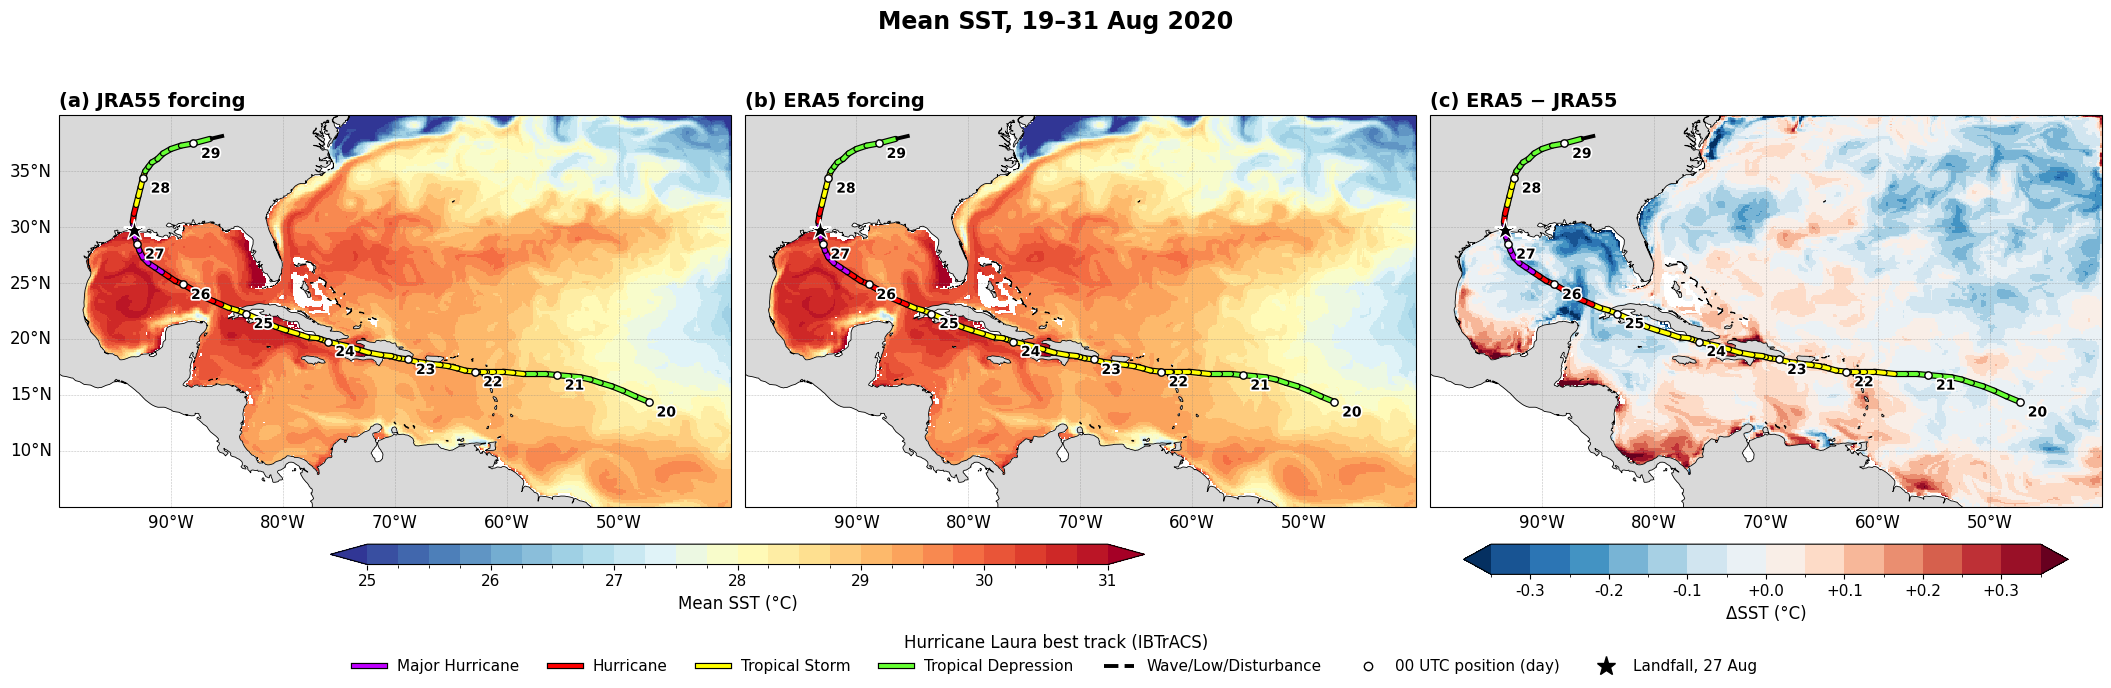

ERA5 - JRA55: area mean -0.018 degC, RMS 0.099 degC, min -1.54, max +0.83


In [2]:
# Run-mean SST in each experiment (a, b) and ERA5 minus JRA55 (c)
mean = {name: da.mean("time") for name, da in sst.items()}
diff = mean["ERA5"] - mean["JRA55"]

lo, hi = np.nanpercentile(np.stack([m.values for m in mean.values()]), [1, 99])
sst_levels = np.arange(np.floor(lo * 2) / 2, np.ceil(hi * 2) / 2 + 0.01, 0.25)
dmax = np.ceil(float(np.nanpercentile(np.abs(diff.values), 99)) * 20) / 20
diff_levels = np.arange(-dmax, dmax + 1e-9, 0.05)
diff_ticks = np.arange(-np.floor(dmax * 10) / 10, dmax + 1e-9, 0.1)
sst_cmap, diff_cmap = plt.get_cmap("RdYlBu_r"), plt.get_cmap("RdBu_r")
sst_norm  = mcolors.BoundaryNorm(sst_levels, sst_cmap.N, extend="both")
diff_norm = mcolors.BoundaryNorm(diff_levels, diff_cmap.N, extend="both")

panels = [("(a) JRA55 forcing", mean["JRA55"], sst_cmap, sst_norm),
          ("(b) ERA5 forcing",  mean["ERA5"],  sst_cmap, sst_norm),
          ("(c) ERA5 \u2212 JRA55", diff, diff_cmap, diff_norm)]

fig, axes = plt.subplots(1, 3, figsize=(21, 6.8), subplot_kw={"projection": PROJ}, layout="constrained")
for i, (ax, (title, data, cmap, norm)) in enumerate(zip(axes, panels)):
    pc = ax.pcolormesh(LONC, LATC, data, transform=PROJ, cmap=cmap, norm=norm)
    add_map(ax, left_labels=(i == 0))
    ax.set_title(title, loc="left", fontweight="bold")
    if i == 1:
        fig.colorbar(pc, ax=axes[:2], orientation="horizontal", shrink=0.6, aspect=40, pad=0.02,
                     label="Mean SST (\u00b0C)", ticks=sst_levels[::4])
    if i == 2:
        fig.colorbar(pc, ax=axes[2], orientation="horizontal", shrink=0.9, aspect=20, pad=0.02,
                     label="\u0394SST (\u00b0C)", ticks=diff_ticks, format="%+.1f")
fig.legend(handles=track_legend_handles(), loc="outside lower center", ncol=7, frameon=False,
           title="Hurricane Laura best track (IBTrACS)", title_fontsize=12)
fig.suptitle(f"Mean SST, {pd.Timestamp(TIMES[0]):%d}\u2013{pd.Timestamp(TIMES[-1]):%d %b %Y}",
             fontsize=17, fontweight="bold")
plt.show()

print(f"ERA5 - JRA55: area mean {float(area_mean(diff)):+.3f} degC, "
      f"RMS {float(np.sqrt(area_mean(diff**2))):.3f} degC, "
      f"min {float(diff.min()):+.2f}, max {float(diff.max()):+.2f}")


## Time series of area-averaged SST

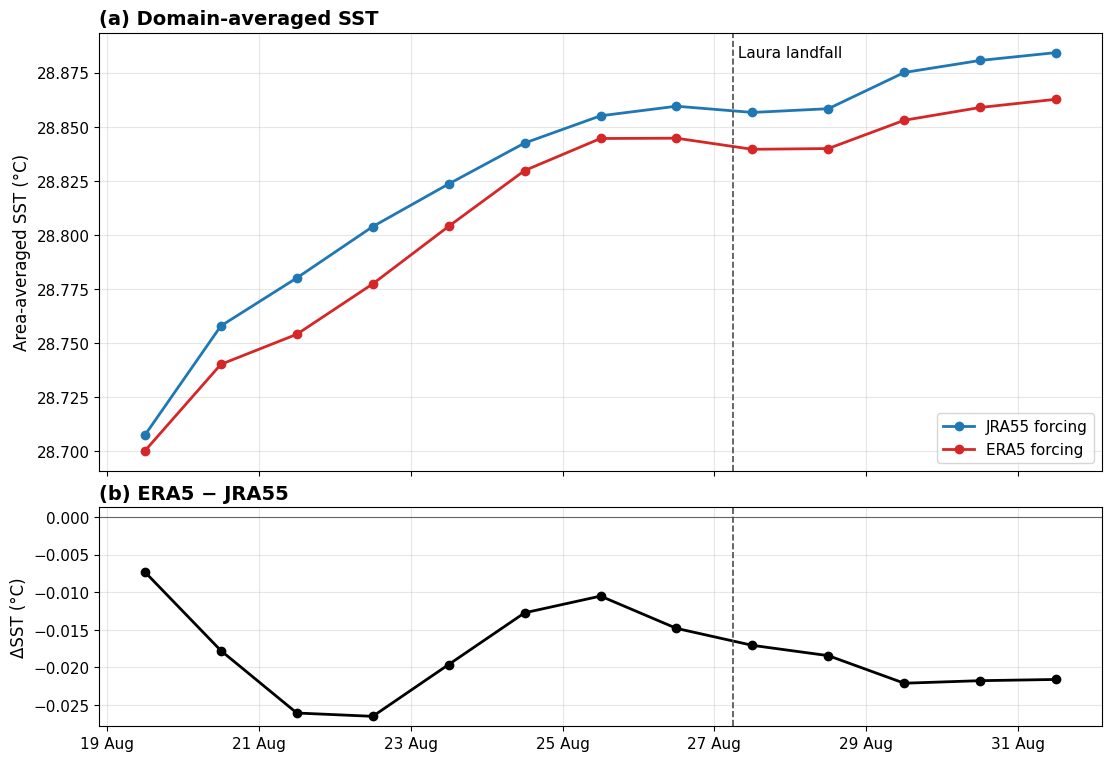

In [3]:
# Daily area-averaged SST in each experiment (a) and the ERA5 minus JRA55 difference (b)
colors = {"JRA55": "tab:blue", "ERA5": "tab:red"}
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, layout="constrained",
                               gridspec_kw={"height_ratios": [2, 1]})
for name, da in sst.items():
    ax1.plot(TIMES, area_mean(da), marker="o", linewidth=2, color=colors[name], label=f"{name} forcing")
ax1.set_ylabel("Area-averaged SST (\u00b0C)")
ax1.set_title("(a) Domain-averaged SST", loc="left", fontweight="bold")
ax1.legend(loc="lower right")

ax2.plot(TIMES, area_mean(sst["ERA5"] - sst["JRA55"]), marker="o", linewidth=2, color="k")
ax2.axhline(0, color="0.4", linewidth=0.8)
ax2.set_ylabel("\u0394SST (\u00b0C)")
ax2.set_title("(b) ERA5 \u2212 JRA55", loc="left", fontweight="bold")

for ax in (ax1, ax2):
    ax.axvline(LANDFALL_TIME, color="0.3", linestyle="--", linewidth=1.2)
    ax.grid(alpha=0.3)
ax1.text(LANDFALL_TIME, 0.97, " Laura landfall", transform=ax1.get_xaxis_transform(), va="top", fontsize=11)
ax2.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.show()


## In situ observations, 20-28 Aug 2020

Platforms inside the model domain while Laura crossed it:

- **Gliders**: IOOS Glider DAC ERDDAP (https://gliders.ioos.us/erddap); ng645 sampled Laura's Gulf crossing.
- **NDBC buoys**: NOAA National Data Buoy Center historical standard meteorological files
  (https://www.ndbc.noaa.gov), buoys that reported between `T0` and `T1`.
- **Stone Mooring** (NDBC 42395, Shell Stones, 26.4°N 90.8°W, ~3000 m water depth): Laura passed directly
  over it on 26 Aug during rapid intensification. NDBC distributes its ADCP currents (upper ~1100 m);
  its thermistor temperatures (8, 50, 100, 150 m; University of Southern Mississippi) are not on NDBC.
- **Argo floats**: profiles listed in the Argo GDAC profile index (https://data-argo.ifremer.fr).

Panel (c) of the forcing figure shows the gliders, buoys and Argo profiles within `TRACK_DISTANCE_DEG`
of Laura's best track, and the Stone Mooring.


In [4]:
# pip install erddapy
from erddapy import ERDDAP

GLIDER_CSV = Path("/glade/u/home/shanru/work/crocodile2026/workspace/data/gliders/ng645_laura.csv")

if not GLIDER_CSV.exists():
    e = ERDDAP(server="https://gliders.ioos.us/erddap", protocol="tabledap")
    e.dataset_id = "ng645-20200730T1909"
    e.variables = ["time", "latitude", "longitude", "depth",
                   "temperature", "salinity", "profile_id"]
    e.constraints = {"time>=": "2020-08-20T00:00:00Z",
                     "time<=": "2020-09-05T00:00:00Z"}

    df = e.to_pandas(parse_dates=True)   # or e.to_xarray()
    GLIDER_CSV.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(GLIDER_CSV, index=False)

glider = pd.read_csv(GLIDER_CSV, parse_dates=[0])
# One position per profile, in time order, for maps
GLIDER_TRACK = (glider.groupby("profile_id")[["time (UTC)", "latitude (degrees_north)", "longitude (degrees_east)"]]
                .first().set_axis(["time", "lat", "lon"], axis=1).sort_values("time"))
print(f"{len(glider)} rows, {glider['profile_id'].nunique()} profiles, "
      f"{glider.iloc[:, 0].min()} to {glider.iloc[:, 0].max()}")
glider.head()


185815 rows, 245 profiles, 2020-08-20 00:25:17+00:00 to 2020-09-04 22:43:13+00:00


,time (UTC),latitude (degrees_north),longitude (degrees_east),depth (m),temperature (Celsius),salinity (1),profile_id
0,2020-08-20 00:25:17+00:00,26.762781,-91.242188,0.119057,30.8201,NaN,1597883177
1,2020-08-20 00:25:17+00:00,26.762781,-91.242188,0.148821,30.8187,NaN,1597883177
2,2020-08-20 00:25:17+00:00,26.762781,-91.242188,0.188507,30.8349,NaN,1597883177
3,2020-08-20 00:25:17+00:00,26.762781,-91.242188,0.168664,30.8342,NaN,1597883177
4,2020-08-20 00:25:17+00:00,26.762781,-91.242188,0.307564,30.8305,NaN,1597883177


In [5]:
# Observation search window and region (the model domain), shared by the glider, buoy and Argo cells
DATA_DIR = Path("/glade/u/home/shanru/work/crocodile2026/workspace/data")
REGION = dict(lon_min=float(EXTENT[0]), lon_max=float(EXTENT[1]), lat_min=float(EXTENT[2]), lat_max=float(EXTENT[3]))
T0, T1 = "2020-08-20", "2020-08-28"

# All IOOS Glider DAC gliders active in REGION between T0 and T1, upper ZMAX_FETCH metres
GLIDER_ERDDAP = "https://gliders.ioos.us/erddap"
ZMAX_FETCH = 200.0
OBS_COLS = ["platform", "source", "profile_id", "time", "lat", "lon", "depth", "temp", "salt"]
GLIDERS_CSV = DATA_DIR / "gliders" / f"ioos_gliders_{T0}_{T1}.csv"


def fetch_gliders(region=REGION, t0=T0, t1=T1, zmax=ZMAX_FETCH):
    from erddapy import ERDDAP
    e = ERDDAP(server=GLIDER_ERDDAP, protocol="tabledap")
    tmin, tmax = f"{t0}T00:00:00Z", f"{t1}T23:59:59Z"
    search = pd.read_csv(e.get_search_url(
        search_for="all", response="csv",
        min_lon=region["lon_min"], max_lon=region["lon_max"],
        min_lat=region["lat_min"], max_lat=region["lat_max"],
        min_time=tmin, max_time=tmax))
    ids = [d for d in search["Dataset ID"] if d != "allDatasets"]
    # use delayed-mode copies when both exist
    delayed = {d[: -len("-delayed")] for d in ids if d.endswith("-delayed")}
    ids = [d for d in ids if d not in delayed]
    print(f"{len(ids)} glider datasets")

    frames = []
    for dsid in ids:
        e.dataset_id = dsid
        e.variables = ["profile_id", "time", "latitude", "longitude", "depth",
                       "temperature", "salinity"]
        e.constraints = {"time>=": tmin, "time<=": tmax,
                         "latitude>=": region["lat_min"], "latitude<=": region["lat_max"],
                         "longitude>=": region["lon_min"], "longitude<=": region["lon_max"],
                         "depth<=": zmax}
        try:
            df = e.to_pandas()
        except Exception as err:
            print(f"  skip {dsid}: {str(err)[:80]}")
            continue
        df.columns = [c.split(" (")[0] for c in df.columns]
        df = df.rename(columns={"latitude": "lat", "longitude": "lon",
                                "temperature": "temp", "salinity": "salt"})
        df["profile_id"] = "glider_" + dsid + "_" + df["profile_id"].astype(str)
        df["platform"] = "glider"
        df["source"] = dsid
        df["time"] = pd.to_datetime(df["time"]).dt.tz_localize(None).astype("datetime64[ns]")
        frames.append(df[OBS_COLS])
        print(f"  {dsid}: {df['profile_id'].nunique()} profiles")
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=OBS_COLS)


if GLIDERS_CSV.exists():
    gliders = pd.read_csv(GLIDERS_CSV, parse_dates=["time"])
else:
    gliders = fetch_gliders()
    GLIDERS_CSV.parent.mkdir(parents=True, exist_ok=True)
    gliders.to_csv(GLIDERS_CSV, index=False)

TRACK_DISTANCE_DEG = 2.0


def distance_to_track_deg(lon, lat, tracks=None):
    """Distance (degrees of latitude, longitude scaled by cos(lat)) from each point to the nearest
    IBTrACS position of Laura (or of the given tracks)."""
    # tracks = (TRACK, MARCO) if tracks is None else tracks
    tracks = (TRACK,) if tracks is None else tracks
    tlon = np.concatenate([np.asarray(t["lon"]) for t in tracks])
    tlat = np.concatenate([np.asarray(t["lat"]) for t in tracks])
    dlon = (np.asarray(lon)[:, None] - tlon[None, :]) * np.cos(np.deg2rad(np.asarray(lat)))[:, None]
    dlat = np.asarray(lat)[:, None] - tlat[None, :]
    return np.hypot(dlon, dlat).min(axis=1)


# One position per profile, in time order, for each glider; keep gliders that come within
# TRACK_DISTANCE_DEG of Laura's best track
all_tracks = {dsid: g.groupby("profile_id")[["time", "lat", "lon"]].first().sort_values("time")
              for dsid, g in gliders.groupby("source")}
closest = {dsid: distance_to_track_deg(t["lon"], t["lat"]).min() for dsid, t in all_tracks.items()}
GLIDER_TRACKS = {dsid: t for dsid, t in all_tracks.items() if closest[dsid] <= TRACK_DISTANCE_DEG}
gliders = gliders[gliders["source"].isin(GLIDER_TRACKS)]

print(f"{len(GLIDER_TRACKS)} of {len(all_tracks)} gliders active {T0} to {T1} in the domain are within {TRACK_DISTANCE_DEG:.0f}\u00b0 of Laura's track: "
      f"{gliders['profile_id'].nunique()} profiles, {len(gliders)} observations to {ZMAX_FETCH:.0f} m")
for dsid in sorted(GLIDER_TRACKS, key=closest.get):
    print(f"  {dsid:32s} closest {closest[dsid]:4.2f}\u00b0")


10 of 31 gliders active 2020-08-20 to 2020-08-28 in the domain are within 2° of Laura's track: 1167 profiles, 187509 observations to 200 m
  ng609-20200717T1224              closest 0.07°
  SG669-20200717T1211              closest 0.12°
  ng314-20200806T2040              closest 0.22°
  ng645-20200730T1909              closest 0.30°
  SG663-20200715T1659              closest 0.44°
  SG610-20200714T1252              closest 0.60°
  SG664-20200714T1238              closest 0.64°
  SG649-20200715T1639              closest 1.04°
  Stommel-20200813T1200            closest 1.69°
  SG630-20200719T1206              closest 1.91°


In [6]:
# NDBC buoys that reported in REGION between T0 and T1, and the Stone Mooring ADCP (NDBC 42395)
NDBC_URL = "https://www.ndbc.noaa.gov"
NDBC_DIR = DATA_DIR / "ndbc"
YEAR = T0[:4]
NDBC_NA = [99.0, 999.0, 9999.0]
# 42395 is retired and absent from the NDBC station table; position as published for the Stone Mooring
STONE_MOORING = dict(station="42395", name="Stone Mooring", lat=26.4, lon=-90.8)


def cached(url, path):
    """Download url to path once."""
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, path)
    return path


def ndbc_station_table():
    """NDBC stations with decimal positions and platform type."""
    rows = []
    for line in open(cached(f"{NDBC_URL}/data/stations/station_table.txt", NDBC_DIR / "station_table.txt")):
        if line.startswith("#"):
            continue
        f = line.split("|")
        m = re.match(r"\s*([\d.]+)\s*([NS])\s*([\d.]+)\s*([EW])", f[6])
        if m:
            rows.append((f[0].lower(), float(m[1]) * (1 if m[2] == "N" else -1),
                         float(m[3]) * (1 if m[4] == "E" else -1), f[2].strip(), f[4].strip()))
    return pd.DataFrame(rows, columns=["station", "lat", "lon", "type", "name"]).set_index("station")


def read_ndbc(path):
    """NDBC standard meteorological or ADCP text file (gzip) with a datetime index."""
    df = pd.read_csv(path, sep=r"\s+", skiprows=2, header=None, na_values=NDBC_NA)
    names = pd.read_csv(path, sep=r"\s+", nrows=0).columns.tolist()
    # ADCP headers can list fewer depth bins than each record carries
    nbin = (df.shape[1] - 5) // 3
    if df.shape[1] > len(names) and names[5] == "DEP01":
        names = names[:5] + [f"{v}{k:02d}" for k in range(1, nbin + 1) for v in ("DEP", "DIR", "SPD")]
    df.columns = names
    df = df.rename(columns={"#YY": "year", "MM": "month", "DD": "day", "hh": "hour", "mm": "minute"})
    df.index = pd.to_datetime(df[["year", "month", "day", "hour", "minute"]])
    return df.drop(columns=["year", "month", "day", "hour", "minute"])


def fetch_ndbc_buoys(region=REGION, t0=T0, t1=T1):
    """Buoys in region with standard meteorological data between t0 and t1 (inclusive days)."""
    listing = cached(f"{NDBC_URL}/data/historical/stdmet/", NDBC_DIR / "stdmet_listing.html").read_text()
    have_year = set(re.findall(rf"([0-9a-z]+)h{YEAR}\.txt\.gz", listing))
    table = ndbc_station_table()
    cand = table[table.index.isin(have_year) & table["type"].str.contains("buoy", case=False)
                 & table["lon"].between(region["lon_min"], region["lon_max"])
                 & table["lat"].between(region["lat_min"], region["lat_max"])]
    rows = []
    for station, info in cand.iterrows():
        f = cached(f"{NDBC_URL}/data/historical/stdmet/{station}h{YEAR}.txt.gz",
                   NDBC_DIR / "stdmet" / f"{station}h{YEAR}.txt.gz")
        obs = read_ndbc(f).loc[t0:f"{t1} 23:59"]
        n = int(obs[["WSPD", "PRES", "WTMP", "WVHT"]].notna().any(axis=1).sum())
        if n:
            rows.append((station, info["lat"], info["lon"], info["type"], info["name"], n))
    return pd.DataFrame(rows, columns=["station", "lat", "lon", "type", "name", "n_obs"]).set_index("station")


def read_ndbc_adcp(path):
    """NDBC ADCP file as eastward/northward current (m/s) on (time, depth)."""
    df = read_ndbc(path)
    depth = df.filter(like="DEP").median().values
    spd = df.filter(like="SPD").values / 100.0
    rad = np.deg2rad(df.filter(like="DIR").values)
    coords = {"time": df.index.values, "depth": depth}
    return xr.Dataset({"u": (("time", "depth"), spd * np.sin(rad), {"units": "m/s"}),
                       "v": (("time", "depth"), spd * np.cos(rad), {"units": "m/s"})}, coords=coords)


buoys_all = fetch_ndbc_buoys()
buoys_all["track_dist"] = distance_to_track_deg(buoys_all["lon"], buoys_all["lat"])
BUOYS = buoys_all[buoys_all["track_dist"] <= TRACK_DISTANCE_DEG]
stone_adcp = read_ndbc_adcp(cached(f"{NDBC_URL}/data/historical/adcp/{STONE_MOORING['station']}a{YEAR}.txt.gz",
                                   DATA_DIR / "stone_mooring" / f"{STONE_MOORING['station']}a{YEAR}.txt.gz"))
stone_adcp = stone_adcp.sel(time=slice(T0, f"{T1} 23:59"))

print(f"{len(BUOYS)} of {len(buoys_all)} NDBC buoys reporting {T0} to {T1} in the domain are within "
      f"{TRACK_DISTANCE_DEG:.0f}\u00b0 of Laura's track:")
print(BUOYS.sort_values("track_dist").round(2).to_string())
good = stone_adcp["u"].notnull().sum("time") > 0
print(f"Stone Mooring ADCP: {stone_adcp.sizes['time']} profiles, {int(good.sum())} depth bins with data "
      f"({float(stone_adcp.depth[good].min()):.0f}-{float(stone_adcp.depth[good].max()):.0f} m), "
      f"closest approach of Laura's track {distance_to_track_deg([STONE_MOORING['lon']], [STONE_MOORING['lat']], tracks=(TRACK,))[0]:.2f}\u00b0")


10 of 75 NDBC buoys reporting 2020-08-20 to 2020-08-28 in the domain are within 2° of Laura's track:
           lat    lon               type                                             name  n_obs  track_dist
station                                                                                                     
42085    17.87 -66.54        Moored Buoy                           Southeast of Ponce, PR   1284        0.17
41115    18.38 -67.28     Waverider Buoy                        Rincon, Puerto Rico (181)    429        0.49
42001    25.92 -89.64  3-meter foam buoy    MID GULF - 180 nm South of Southwest Pass, LA   1294        0.60
41056    18.26 -65.46        Moored Buoy                               Vieques Island, PR   1271        0.70
41052    18.25 -64.76        Moored Buoy                            South of St. John, VI    334        0.77
42060    16.43 -63.21  3-meter foam buoy       Caribbean Valley - 63 NM WSW of Montserrat   1296        0.78
41053    18.47 -66.10      

In [7]:
# Argo profiles in REGION between T0 and T1, from the GDAC profile index; profile files cached
ARGO_GDAC = "https://data-argo.ifremer.fr"
ARGO_DIR = DATA_DIR / "argo"


def fetch_argo_profiles(region=REGION, t0=T0, t1=T1):
    index = cached(f"{ARGO_GDAC}/ar_index_global_prof.txt.gz", ARGO_DIR / "ar_index_global_prof.txt.gz")
    df = pd.read_csv(index, comment="#", dtype={"date": str})
    df = df.dropna(subset=["date", "latitude", "longitude"])
    df["time"] = pd.to_datetime(df["date"], format="%Y%m%d%H%M%S", errors="coerce")
    df = df[df["time"].between(pd.Timestamp(t0), pd.Timestamp(f"{t1} 23:59:59"))
            & df["longitude"].between(region["lon_min"], region["lon_max"])
            & df["latitude"].between(region["lat_min"], region["lat_max"])]
    df = df.rename(columns={"latitude": "lat", "longitude": "lon"})
    df["platform"] = df["file"].str.split("/").str[1]
    for f in df["file"]:
        cached(f"{ARGO_GDAC}/dac/{f}", ARGO_DIR / "profiles" / Path(f).name)
    return df[["platform", "time", "lat", "lon", "file"]].reset_index(drop=True)


argo_all = fetch_argo_profiles()
argo_all["track_dist"] = distance_to_track_deg(argo_all["lon"], argo_all["lat"])
ARGO = argo_all[argo_all["track_dist"] <= TRACK_DISTANCE_DEG]
print(f"Argo: {len(argo_all)} profiles from {argo_all['platform'].nunique()} floats in the domain {T0} to {T1}; "
      f"{len(ARGO)} profiles from {ARGO['platform'].nunique()} floats within {TRACK_DISTANCE_DEG:.0f}\u00b0 of Laura's track")
print(ARGO.sort_values("time")[["platform", "time", "lat", "lon", "track_dist"]].round({"lat": 2, "lon": 2, "track_dist": 2}).to_string(index=False))


Argo: 232 profiles from 189 floats in the domain 2020-08-20 to 2020-08-28; 46 profiles from 32 floats within 2° of Laura's track
platform                time   lat    lon  track_dist
 4903234 2020-08-20 05:02:33 22.70 -84.68        0.16
 3901686 2020-08-20 05:48:20 17.80 -56.64        0.91
 4903248 2020-08-20 10:49:04 25.95 -90.91        0.11
 4903251 2020-08-20 12:30:48 23.90 -83.41        1.44
 6901182 2020-08-20 15:43:00 19.29 -66.64        1.49
 4903256 2020-08-20 18:35:17 25.61 -89.85        0.31
 4903252 2020-08-21 11:24:59 23.33 -83.43        0.96
 4903233 2020-08-22 02:48:47 24.10 -82.40        1.97
 4903240 2020-08-22 08:22:43 25.37 -88.14        0.83
 4903250 2020-08-22 09:52:28 24.30 -84.18        1.60
 4903249 2020-08-22 10:37:21 25.06 -88.43        0.45
 6902713 2020-08-22 23:26:00 16.31 -69.81        2.00
 4903236 2020-08-23 08:07:20 23.28 -82.95        1.03
 4903258 2020-08-23 09:37:45 24.69 -84.56        1.81
 4901623 2020-08-23 11:46:19 17.78 -58.99        0.87
 690285

In [8]:
# Summary of the observational datasets, 20-28 Aug 2020 in the model domain
adcp_depths = stone_adcp["depth"].values[stone_adcp["u"].notnull().any("time").values]
n_glider_profiles = sum(len(t) for t in all_tracks.values())
n_track_profiles = sum(len(t) for t in GLIDER_TRACKS.values())
near = f"Within {TRACK_DISTANCE_DEG:.0f}\u00b0 of Laura"
DATASETS = pd.DataFrame([
    dict(Dataset="IBTrACS v04r01", Provider="NOAA NCEI", Variables="Position, min SLP, max wind, status",
         Sampling="3-hourly best track",
         # **{"In domain": f"Laura {len(TRACK['time'])} fixes, Marco {len(MARCO['time'])} fixes", near: "\u2014"},
         **{"In domain": f"Laura {len(TRACK['time'])} fixes", near: "\u2014"},
         Cache="data/ibtracs/"),
    dict(Dataset="Gliders", Provider="IOOS Glider DAC (ERDDAP)", Variables=f"T, S profiles (0-{ZMAX_FETCH:.0f} m)",
         Sampling="Sawtooth profiles, ~hours",
         **{"In domain": f"{len(all_tracks)} gliders, {n_glider_profiles} profiles",
            near: f"{len(GLIDER_TRACKS)} gliders, {n_track_profiles} profiles"},
         Cache=f"data/gliders/{GLIDERS_CSV.name}"),
    dict(Dataset="NDBC buoys", Provider="NOAA NDBC", Variables="Wind, SLP, SST, waves (stdmet)",
         Sampling="10-60 min",
         **{"In domain": f"{len(buoys_all)} buoys", near: f"{len(BUOYS)} buoys"},
         Cache="data/ndbc/stdmet/"),
    dict(Dataset="Stone Mooring (NDBC 42395)", Provider="NOAA NDBC (ADCP); USM (thermistors)",
         Variables="Current speed/direction profiles",
         Sampling=f"{len(stone_adcp.time)} ADCP profiles",
         **{"In domain": f"1 mooring, {len(adcp_depths)} bins {adcp_depths.min():.0f}-{adcp_depths.max():.0f} m",
            near: f"Yes ({distance_to_track_deg([STONE_MOORING['lon']], [STONE_MOORING['lat']], tracks=(TRACK,))[0]:.2f}\u00b0 from Laura)"},
         Cache="data/stone_mooring/"),
    dict(Dataset="Argo floats", Provider="Argo GDAC (Ifremer)", Variables="T, S profiles (0-2000 m)",
         Sampling="~10-day cycles",
         **{"In domain": f"{argo_all['platform'].nunique()} floats, {len(argo_all)} profiles",
            near: f"{ARGO['platform'].nunique()} floats, {len(ARGO)} profiles"},
         Cache="data/argo/profiles/"),
]).set_index("Dataset")
DATASETS.style.set_properties(**{"text-align": "left"})


,Provider,Variables,Sampling,In domain,Within 2° of Laura,Cache
Dataset,,,,,,
IBTrACS v04r01,NOAA NCEI,"Position, min SLP, max wind, status",3-hourly best track,Laura 79 fixes,—,data/ibtracs/
Gliders,IOOS Glider DAC (ERDDAP),"T, S profiles (0-200 m)","Sawtooth profiles, ~hours","31 gliders, 17290 profiles","10 gliders, 1167 profiles",data/gliders/ioos_gliders_2020-08-20_2020-08-28.csv
NDBC buoys,NOAA NDBC,"Wind, SLP, SST, waves (stdmet)",10-60 min,75 buoys,10 buoys,data/ndbc/stdmet/
Stone Mooring (NDBC 42395),NOAA NDBC (ADCP); USM (thermistors),Current speed/direction profiles,533 ADCP profiles,"1 mooring, 58 bins 4-892 m",Yes (0.40° from Laura),data/stone_mooring/
Argo floats,Argo GDAC (Ifremer),"T, S profiles (0-2000 m)",~10-day cycles,"189 floats, 232 profiles","32 floats, 46 profiles",data/argo/profiles/


## Laura in the atmospheric forcing: JRA55 vs ERA5 vs IBTrACS

Storm centre in each DATM forcing dataset, found with one of two methods, chosen per storm in `TRACK_METHOD`
(Laura: independent; Hurricane Marco, commented out, used guided because it is too weak and broad in
both reanalyses for the independent search to follow):

- **independent** (default): seeded once at genesis with the sea-level-pressure (SLP) minimum within
  `SEED_RADIUS` of the first IBTrACS fix; afterwards each centre is the SLP minimum within `STEP_RADIUS`
  of the previous centre extrapolated along its last motion. IBTrACS is not used after the first time.
- **guided**: at every time, the SLP minimum within `SEARCH_RADIUS` of the IBTrACS position.

Maximum 10 m wind is the largest 10 m wind speed within `SEARCH_RADIUS` of the centre. JRA55 is 3-hourly on the TL319 (~0.56°) grid, ERA5 hourly at 0.25°.
IBTrACS winds are NHC 1-minute sustained maxima, so gridded reanalysis winds are expected to be weaker.

In [9]:
# Forcing files read by DATM in each case (see CaseDocs/datm.streams.xml)
JRA_DIR  = Path("/glade/campaign/cesm/cesmdata/inputdata/ocn/jra55/v1.5_noleap")
ERA5_DIR = Path("/glade/work/shanru/crocodile2026/era5_datm/hurcn_gomcar_2020")
FORCING_FILES = {
    "JRA55": {v: JRA_DIR / f"JRA.v1.5.{v}.TL319.2020.210504.nc" for v in ("slp", "u_10", "v_10")},
    "ERA5":  {v: ERA5_DIR / f"ERA5.{v}.20200817_20200903.nc" for v in ("slp", "u_10", "v_10")},
}
# Search used for each storm ("independent" or "guided"). Marco is a weak, broad low in both
# reanalyses (1004-1007 hPa vs 991 hPa in IBTrACS) and the independent search loses it on 21-22 Aug.
TRACK_METHOD  = {"Laura": "independent", "Marco": "guided"}
SEARCH_RADIUS = 3.0   # degrees of latitude: guided search, and max-wind radius around the centre
SEED_RADIUS   = 1.5   # independent search: around the first IBTrACS fix
STEP_RADIUS   = 1.0   # independent search: plus 0.15 deg per hour of forcing time step
MS_PER_KT = 0.514444
BOX = dict(lon=(255.0, 325.0), lat=(0.0, 45.0))   # 0-360 longitudes, as in the forcing files
# STORMS = {"Laura": TRACK, "Marco": MARCO}
STORMS = {"Laura": TRACK}
T_FIRST = min(s["time"][0] for s in STORMS.values())
T_LAST  = max(s["time"][-1] for s in STORMS.values())


def track_position(when, track=TRACK):
    """IBTrACS position linearly interpolated to a time, or None outside the track."""
    t = np.datetime64(when, "m").astype(float)
    tt = track["time"].astype("datetime64[m]").astype(float)
    if t < tt[0] or t > tt[-1]:
        return None
    return np.interp(t, tt, track["lon"]), np.interp(t, tt, track["lat"])


def open_forcing(files):
    """slp (hPa) and 10 m wind speed (m/s) over BOX during the storms' lifetimes, on a datetime64 time axis."""
    fields = []
    for var, path in files.items():
        ds = xr.open_dataset(path, decode_times=False)
        ds = ds.rename({k: v for k, v in {"latitude": "lat", "longitude": "lon"}.items() if k in ds.dims})
        # JRA55 v1.5 uses a noleap calendar, so decode to cftime and go through ISO strings.
        time = decode_cf_datetime(ds["time"].values, ds["time"].attrs["units"], ds["time"].attrs["calendar"],
                                  use_cftime=True)
        time = pd.DatetimeIndex([t.isoformat() for t in time]).round("min")
        da = ds[var].assign_coords(time=time).sel(lon=slice(*BOX["lon"]), lat=slice(*BOX["lat"]))
        fields.append(da.sel(time=slice(T_FIRST, T_LAST)).load())
    slp, u, v = fields
    return slp / 100.0, np.hypot(u, v)


def storm_period(da, track):
    return da.sel(time=slice(track["time"][0], track["time"][-1]))


def find_storm(slp, wspd, track=TRACK, radius=SEARCH_RADIUS):
    """Track the storm through slp/wspd, guided by the IBTrACS position at each time."""
    slp, wspd = storm_period(slp, track), storm_period(wspd, track)
    lon2d, lat2d = np.meshgrid((slp["lon"].values + 180.0) % 360.0 - 180.0, slp["lat"].values)
    rows = []
    for k, t in enumerate(slp["time"].values):
        glon, glat = track_position(t, track)
        near = np.hypot((lon2d - glon) * np.cos(np.deg2rad(glat)), lat2d - glat) <= radius
        p = np.where(near, slp.values[k], np.inf)
        j = np.unravel_index(np.argmin(p), p.shape)
        clon, clat = lon2d[j], lat2d[j]
        core = np.hypot((lon2d - clon) * np.cos(np.deg2rad(clat)), lat2d - clat) <= radius
        rows.append((t, clon, clat, p[j], np.nanmax(np.where(core, wspd.values[k], np.nan))))
    return pd.DataFrame(rows, columns=["time", "lon", "lat", "pres", "wind"]).set_index("time")


def find_storm_independent(slp, wspd, track=TRACK):
    """Track the storm through slp/wspd from a single seed at the first IBTrACS fix, following the SLP
    minimum near the previous centre extrapolated along its last displacement."""
    slp, wspd = storm_period(slp, track), storm_period(wspd, track)
    lon2d, lat2d = np.meshgrid((slp["lon"].values + 180.0) % 360.0 - 180.0, slp["lat"].values)
    dt_h = (slp["time"].values[1] - slp["time"].values[0]) / np.timedelta64(1, "h")
    rows = []
    for k, t in enumerate(slp["time"].values):
        if k == 0:
            (glon, glat), radius = track_position(t, track), SEED_RADIUS
        else:
            glon, glat = rows[-1][1:3]
            if k > 1:
                glon += rows[-1][1] - rows[-2][1]
                glat += rows[-1][2] - rows[-2][2]
            radius = STEP_RADIUS + 0.15 * dt_h
        near = np.hypot((lon2d - glon) * np.cos(np.deg2rad(glat)), lat2d - glat) <= radius
        p = np.where(near, slp.values[k], np.inf)
        j = np.unravel_index(np.argmin(p), p.shape)
        clon, clat = lon2d[j], lat2d[j]
        core = np.hypot((lon2d - clon) * np.cos(np.deg2rad(clat)), lat2d - clat) <= SEARCH_RADIUS
        rows.append((t, clon, clat, p[j], np.nanmax(np.where(core, wspd.values[k], np.nan))))
    return pd.DataFrame(rows, columns=["time", "lon", "lat", "pres", "wind"]).set_index("time")


def distance_km(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.deg2rad, (lon1, lat1, lon2, lat2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


def best_track(track):
    return pd.DataFrame({"lon": track["lon"], "lat": track["lat"], "pres": track["pres"],
                         "wind": track["wind"] * MS_PER_KT}, index=pd.DatetimeIndex(track["time"]))


BEST = {sname: best_track(track) for sname, track in STORMS.items()}
best = BEST["Laura"]
forcing = {name: open_forcing(files) for name, files in FORCING_FILES.items()}
tracks = {method: {sname: {name: finder(*fields, track=track) for name, fields in forcing.items()}
                   for sname, track in STORMS.items()}
          for method, finder in (("independent", find_storm_independent), ("guided", find_storm))}
STORM_TRACKS = {sname: tracks[TRACK_METHOD[sname]][sname] for sname in STORMS}
storm = STORM_TRACKS["Laura"]

for method, by_storm in tracks.items():
    for sname, result in by_storm.items():
        ib = BEST[sname]
        for name, df in result.items():
            ref = ib.reindex(ib.index.union(df.index)).interpolate("time").loc[df.index]
            err = distance_km(df["lon"], df["lat"], ref["lon"], ref["lat"])
            print(f"{method:11s} {sname:5s} {name:6s} {len(df):3d} times | min pressure {df['pres'].min():6.1f} hPa "
                  f"(IBTrACS {ib['pres'].min():.0f}) | max wind {df['wind'].max():4.1f} m/s "
                  f"(IBTrACS {ib['wind'].max():.1f}) | position error mean {err.mean():4.0f} km, max {err.max():4.0f} km")


independent Laura JRA55   75 times | min pressure  995.3 hPa (IBTrACS 937) | max wind 23.3 m/s (IBTrACS 66.9) | position error mean   82 km, max  196 km
independent Laura ERA5   223 times | min pressure  978.2 hPa (IBTrACS 937) | max wind 30.0 m/s (IBTrACS 66.9) | position error mean   51 km, max  264 km
guided      Laura JRA55   75 times | min pressure  995.3 hPa (IBTrACS 937) | max wind 23.3 m/s (IBTrACS 66.9) | position error mean   90 km, max  333 km
guided      Laura ERA5   223 times | min pressure  978.2 hPa (IBTrACS 937) | max wind 30.0 m/s (IBTrACS 66.9) | position error mean   56 km, max  332 km


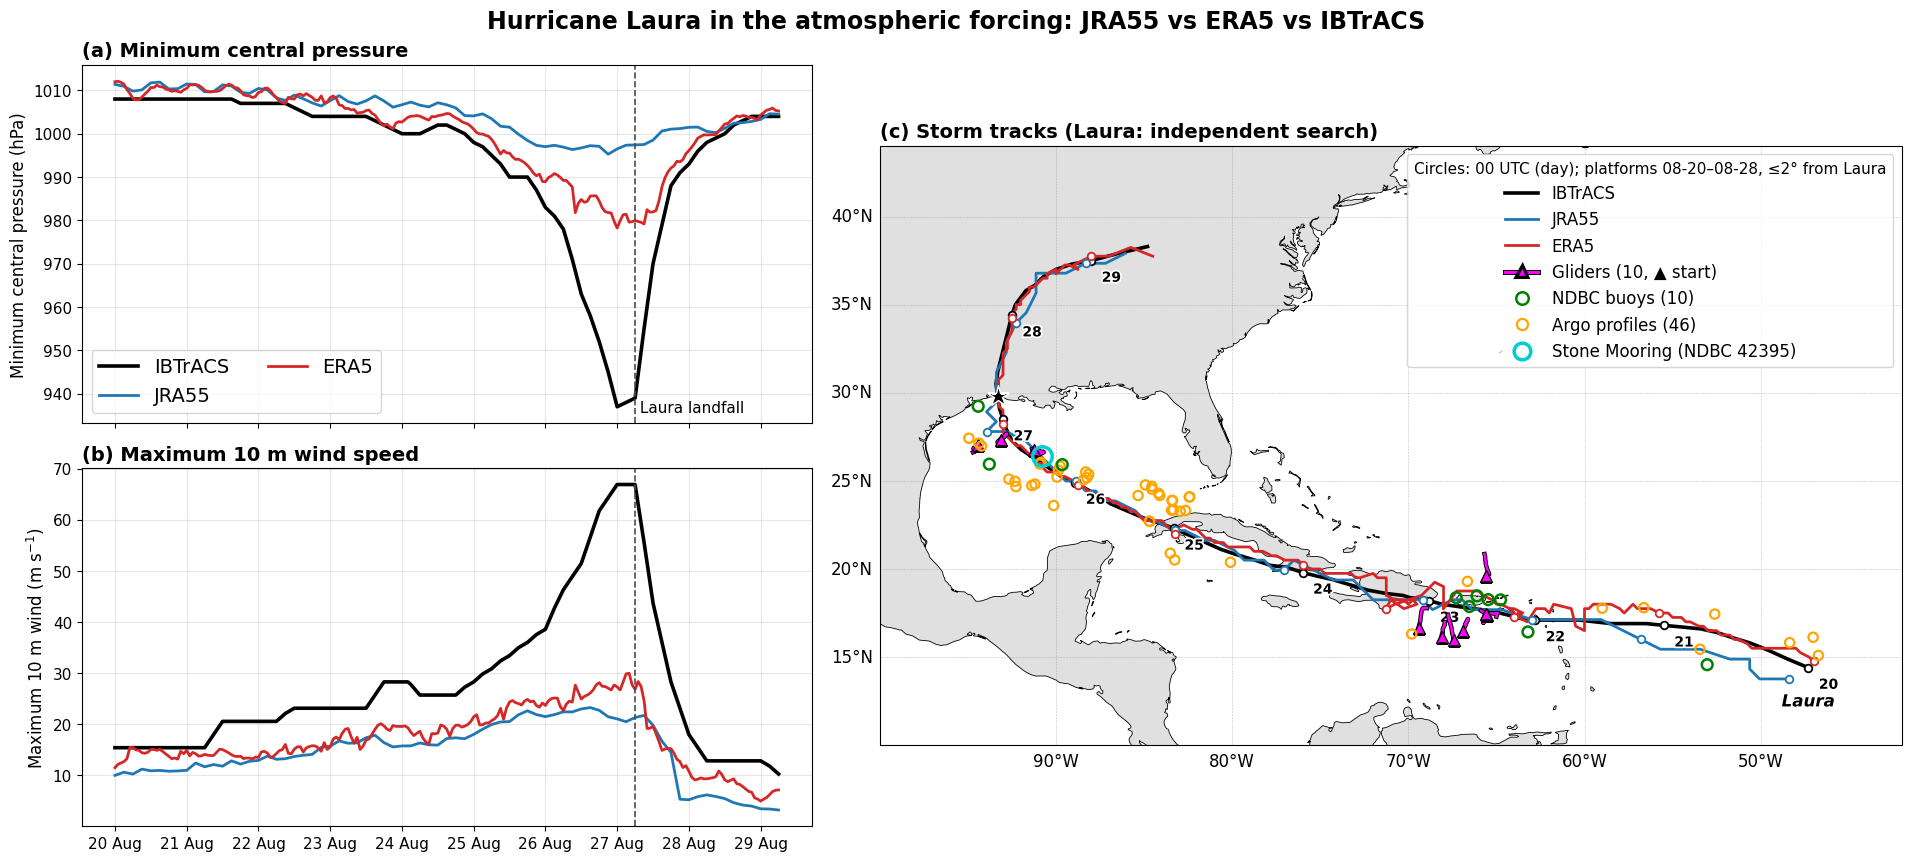

In [10]:
# Left: minimum central pressure and maximum 10 m wind; right: tracks. Laura solid (Marco dashed, commented out).
SOURCE_STYLE = {"IBTrACS": ("k", 2.6), "JRA55": ("tab:blue", 2.0), "ERA5": ("tab:red", 2.0)}
# STORM_STYLE = {"Laura": "-", "Marco": "--"}
STORM_STYLE = {"Laura": "-"}
GLIDER_COLOR = "magenta"
BUOY_COLOR, ARGO_COLOR, MOORING_COLOR = "green", "orange", "darkturquoise"


def storm_sources(sname):
    """(name, track DataFrame, colour, line width) for IBTrACS, JRA55 and ERA5 of one storm."""
    dfs = {"IBTrACS": BEST[sname], **STORM_TRACKS[sname]}
    return [(name, dfs[name], *SOURCE_STYLE[name]) for name in SOURCE_STYLE]


source_handles = [plt.Line2D([], [], color=c, linewidth=lw, label=name) for name, (c, lw) in SOURCE_STYLE.items()]
storm_handles = [plt.Line2D([], [], color="0.35", linewidth=2.0, linestyle=ls, label=sname)
                 for sname, ls in STORM_STYLE.items()] if len(STORM_STYLE) > 1 else []

fig = plt.figure(figsize=(19, 8.5), layout="constrained")
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.4])
axp = fig.add_subplot(gs[0, 0])
axw = fig.add_subplot(gs[1, 0], sharex=axp)
axm = fig.add_subplot(gs[:, 1], projection=PROJ)

for sname, ls in STORM_STYLE.items():
    for name, df, color, lw in storm_sources(sname):
        axp.plot(df.index, df["pres"], color=color, linewidth=lw, linestyle=ls)
        axw.plot(df.index, df["wind"], color=color, linewidth=lw, linestyle=ls)
axp.set_ylabel("Minimum central pressure (hPa)")
axp.set_title("(a) Minimum central pressure", loc="left", fontweight="bold")
axp.legend(handles=source_handles + storm_handles, loc="lower left", fontsize=14, ncol=2)
axw.set_ylabel("Maximum 10 m wind (m s$^{-1}$)")
axw.set_title("(b) Maximum 10 m wind speed", loc="left", fontweight="bold")
for ax in (axp, axw):
    ax.axvline(LANDFALL_TIME, color="0.3", linestyle="--", linewidth=1.2)
    ax.grid(alpha=0.3)
axp.text(LANDFALL_TIME, 0.03, " Laura landfall", transform=axp.get_xaxis_transform(), fontsize=11)
axw.xaxis.set_major_locator(mdates.DayLocator())
axw.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.setp(axp.get_xticklabels(), visible=False)

axm.set_extent([-100, -42, 10, 44], crs=PROJ)
axm.add_feature(cfeature.LAND, facecolor="0.88", zorder=1)
axm.coastlines(resolution="50m", linewidth=0.6, zorder=2)
gl = axm.gridlines(draw_labels=True, linewidth=0.4, color="0.5", alpha=0.5, linestyle="--")
gl.top_labels = gl.right_labels = False
WHITE = [pe.withStroke(linewidth=2.5, foreground="white")]


def draw_tracks(ax):
    for sname, ls in STORM_STYLE.items():
        for name, df, color, lw in storm_sources(sname):
            ax.plot(df["lon"], df["lat"], color=color, linewidth=lw, linestyle=ls, transform=PROJ, zorder=4)
            at00 = df.index.hour == 0
            ax.scatter(df["lon"][at00], df["lat"][at00], s=30, facecolors="white", edgecolors=color,
                       linewidths=1.3, transform=PROJ, zorder=5)
        ib = BEST[sname]
        dx = 0.6 if sname == "Laura" else -1.6
        for t, row in ib[ib.index.hour == 0].iterrows():
            ax.text(row["lon"] + dx, row["lat"] - 1.2, f"{t:%d}", fontsize=10, fontweight="bold",
                    path_effects=WHITE, transform=PROJ, zorder=6, clip_on=True)
        ax.text(ib["lon"].iloc[0], ib["lat"].iloc[0] - 2.2, sname, fontsize=12, fontweight="bold",
                fontstyle="italic", ha="center", path_effects=WHITE, transform=PROJ, zorder=6)
    ax.plot(*LANDFALL, marker="*", color="k", markeredgecolor="white", markersize=16, transform=PROJ, zorder=6)
    for track in GLIDER_TRACKS.values():
        ax.plot(track["lon"], track["lat"], color=GLIDER_COLOR, linewidth=1.8,
                path_effects=[pe.Stroke(linewidth=3.2, foreground="k"), pe.Normal()],
                transform=PROJ, zorder=7)
        ax.plot(track["lon"].iloc[0], track["lat"].iloc[0], marker="^", color=GLIDER_COLOR,
                markeredgecolor="k", markersize=8, transform=PROJ, zorder=8)
    ax.scatter(ARGO["lon"], ARGO["lat"], s=45, marker="o", facecolors="none", edgecolors=ARGO_COLOR,
               linewidths=1.6, transform=PROJ, zorder=8)
    ax.scatter(BUOYS["lon"], BUOYS["lat"], s=60, marker="o", facecolors="none", edgecolors=BUOY_COLOR,
               linewidths=1.8, transform=PROJ, zorder=8)
    ax.plot(STONE_MOORING["lon"], STONE_MOORING["lat"], marker="o", markersize=14, markerfacecolor="none",
            markeredgecolor=MOORING_COLOR, markeredgewidth=2.5, transform=PROJ, zorder=9)


draw_tracks(axm)
glider_handle = plt.Line2D([], [], color=GLIDER_COLOR, linewidth=2.2, marker="^", markevery=[0],
                           markeredgecolor="k",
                           label=f"Gliders ({len(GLIDER_TRACKS)}, \u25b2 start)",
                           path_effects=[pe.Stroke(linewidth=3.6, foreground="k"), pe.Normal()])
platform_handles = [
    glider_handle,
    plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="none", markeredgecolor=BUOY_COLOR,
               markeredgewidth=1.8, markersize=9,
               label=f"NDBC buoys ({len(BUOYS)})"),
    plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="none", markeredgecolor=ARGO_COLOR,
               markeredgewidth=1.6, markersize=8,
               label=f"Argo profiles ({len(ARGO)})"),
    plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="none", markeredgecolor=MOORING_COLOR,
               markeredgewidth=2.5, markersize=12,
               label="Stone Mooring (NDBC 42395)"),
]
axm.legend(handles=source_handles + storm_handles + platform_handles, loc="upper right", fontsize=12,
           title=f"Circles: 00 UTC (day); platforms {T0[5:]}\u2013{T1[5:]}, \u2264{TRACK_DISTANCE_DEG:.0f}\u00b0 from Laura",
           title_fontsize=11)
axm.set_title("(c) Storm tracks (" + ", ".join(f"{s}: {TRACK_METHOD[s]}" for s in STORMS) + " search)",
              loc="left", fontweight="bold")

fig.suptitle("Hurricane Laura in the atmospheric forcing: JRA55 vs ERA5 vs IBTrACS",
             fontsize=17, fontweight="bold")
plt.show()


## Waves: JRA55 vs ERA5 forcing

Hourly WW3 history from the wave-output reruns `hurcn_gomcar_ocn_wav.002` (JRA55) and
`hurcn_gomcar_ocn_wav_era5.002` (ERA5). These are identical to the `.001` cases apart from
`HIST_OPTION=nhours`, `HIST_N=1`. WW3 runs on the MOM6 grid, so the SST grid and land mask are reused.
Near-storm values are taken within `STORM_RADIUS_KM` of the IBTrACS centre.

In [11]:
WAVE_EXPS = {"JRA55": "hurcn_gomcar_ocn_wav.002", "ERA5": "hurcn_gomcar_ocn_wav_era5.002"}
STORM_RADIUS_KM = 300.0


def open_waves(case, variables=("HS", "FP0")):
    """Hourly WW3 fields of one case on the MOM6 (yh, xh) grid, land masked."""
    files = sorted((ARCHIVE / case / "wav" / "hist").glob(f"{case}.ww3.hi.*.nc"))
    ds = xr.open_mfdataset(files, combine="nested", concat_dim="time", data_vars="minimal",
                           coords="minimal", compat="override")
    ds = ds[list(variables)].rename({"ny": "yh", "nx": "xh"})
    return ds.where(WET).load()


waves = {name: open_waves(case) for name, case in WAVE_EXPS.items()}
if not np.array_equal(waves["JRA55"].time.values, waves["ERA5"].time.values):
    raise ValueError("The two wave experiments have different time axes")
WAVE_TIMES = waves["JRA55"].time.values

ww3 = xr.open_dataset(next((ARCHIVE / WAVE_EXPS["JRA55"] / "wav" / "hist").glob("*.ww3.hi.*.nc")))
WLON = (ww3["lon"].values + 180.0) % 360.0 - 180.0
WLAT = ww3["lat"].values


def near_storm(ds):
    """Hourly maximum HS within STORM_RADIUS_KM of Laura's IBTrACS centre, and the peak period there."""
    rows = []
    for k, t in enumerate(WAVE_TIMES):
        pos = track_position(t)
        if pos is None:
            continue
        hs = np.where(distance_km(WLON, WLAT, *pos) <= STORM_RADIUS_KM, ds["HS"].values[k], np.nan)
        if np.all(np.isnan(hs)):
            continue
        j = np.unravel_index(np.nanargmax(hs), hs.shape)
        rows.append((t, hs[j], 1.0 / ds["FP0"].values[k][j]))
    return pd.DataFrame(rows, columns=["time", "hs", "tp"]).set_index("time")


hs_max = {name: ds["HS"].max("time") for name, ds in waves.items()}
storm_waves = {name: near_storm(ds) for name, ds in waves.items()}

print(f"{len(WAVE_TIMES)} hourly fields: {WAVE_TIMES[0]} to {WAVE_TIMES[-1]}")
for name in WAVE_EXPS:
    df = storm_waves[name]
    print(f"{name:6s} max HS {float(hs_max[name].max()):5.2f} m | near Laura: max HS {df['hs'].max():5.2f} m "
          f"at {df['hs'].idxmax()}, Tp there {df.loc[df['hs'].idxmax(), 'tp']:4.1f} s")


312 hourly fields: 2020-08-19T01:00:00.000000000 to 2020-09-01T00:00:00.000000000
JRA55  max HS  7.08 m | near Laura: max HS  7.08 m at 2020-08-26 16:00:00, Tp there 11.3 s
ERA5   max HS  8.32 m | near Laura: max HS  8.32 m at 2020-08-26 20:00:00, Tp there 11.8 s


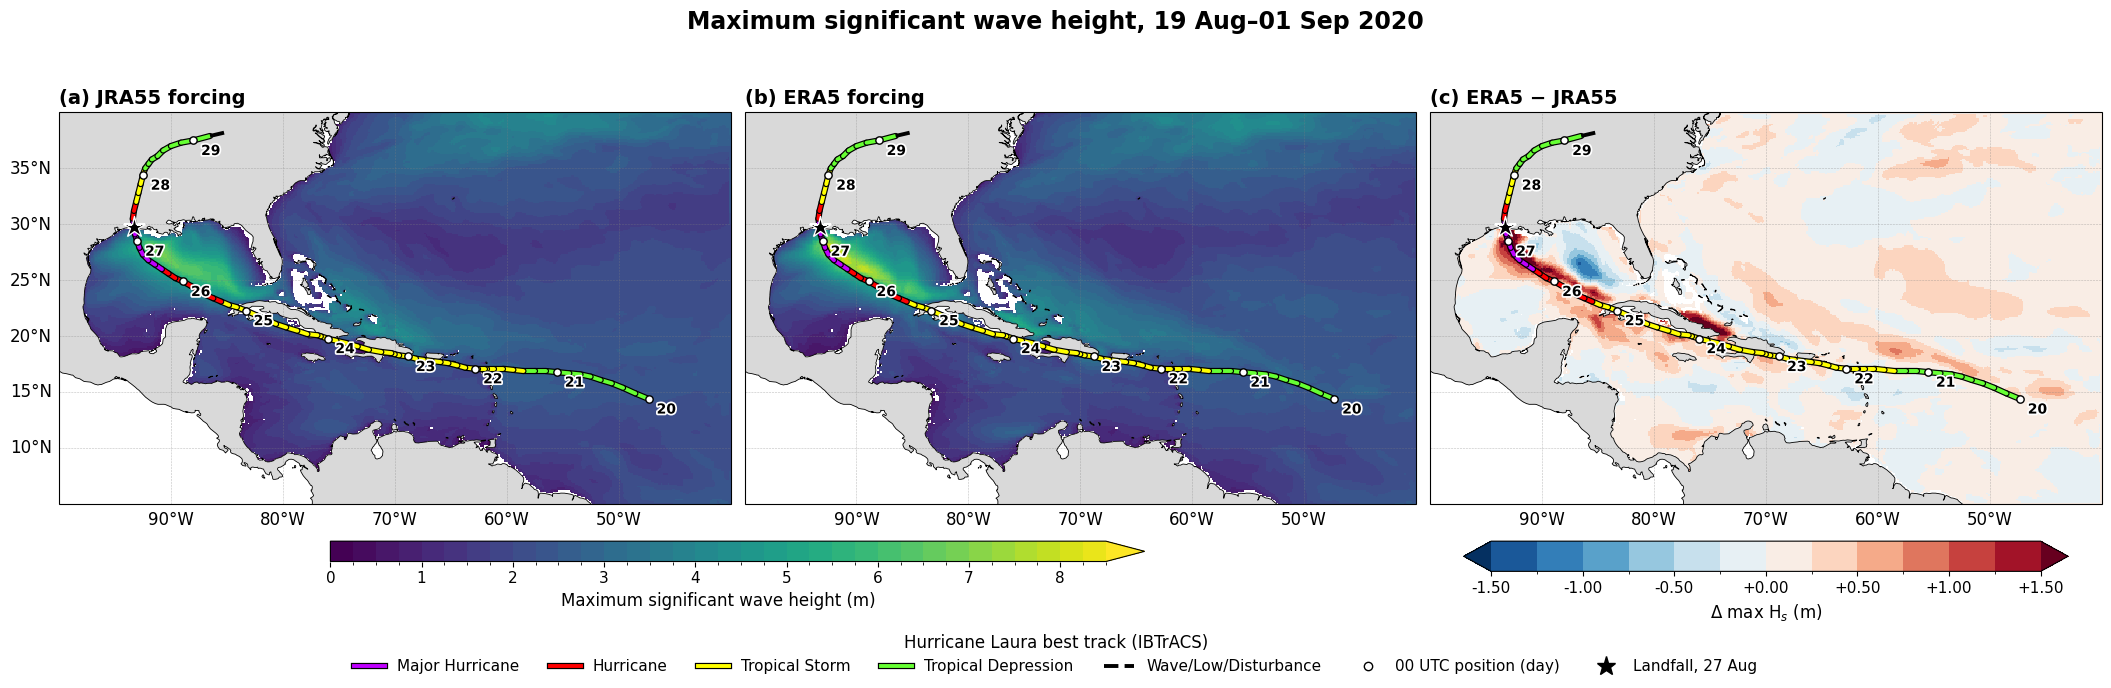

In [12]:
# Maximum significant wave height over the run in each experiment (a, b) and ERA5 minus JRA55 (c)
hs_diff = hs_max["ERA5"] - hs_max["JRA55"]

hs_top = np.ceil(float(max(m.max() for m in hs_max.values())) * 2) / 2
hs_levels = np.arange(0.0, hs_top + 1e-9, 0.25)
hmax = np.ceil(float(np.nanpercentile(np.abs(hs_diff.values), 99.5)) * 4) / 4
hdiff_levels = np.linspace(-hmax, hmax, 13)
hs_cmap, hdiff_cmap = plt.get_cmap("viridis"), plt.get_cmap("RdBu_r")
hs_norm    = mcolors.BoundaryNorm(hs_levels, hs_cmap.N, extend="max")
hdiff_norm = mcolors.BoundaryNorm(hdiff_levels, hdiff_cmap.N, extend="both")

panels = [("(a) JRA55 forcing", hs_max["JRA55"], hs_cmap, hs_norm),
          ("(b) ERA5 forcing",  hs_max["ERA5"],  hs_cmap, hs_norm),
          ("(c) ERA5 \u2212 JRA55", hs_diff, hdiff_cmap, hdiff_norm)]

fig, axes = plt.subplots(1, 3, figsize=(21, 6.8), subplot_kw={"projection": PROJ}, layout="constrained")
for i, (ax, (title, data, cmap, norm)) in enumerate(zip(axes, panels)):
    pc = ax.pcolormesh(LONC, LATC, data, transform=PROJ, cmap=cmap, norm=norm)
    add_map(ax, left_labels=(i == 0))
    ax.set_title(title, loc="left", fontweight="bold")
    if i == 1:
        fig.colorbar(pc, ax=axes[:2], orientation="horizontal", shrink=0.6, aspect=40, pad=0.02,
                     label="Maximum significant wave height (m)", ticks=hs_levels[::4])
    if i == 2:
        fig.colorbar(pc, ax=axes[2], orientation="horizontal", shrink=0.9, aspect=20, pad=0.02,
                     label="\u0394 max H$_s$ (m)", ticks=hdiff_levels[::2], format="%+.2f")
fig.legend(handles=track_legend_handles(), loc="outside lower center", ncol=7, frameon=False,
           title="Hurricane Laura best track (IBTrACS)", title_fontsize=12)
fig.suptitle(f"Maximum significant wave height, {pd.Timestamp(WAVE_TIMES[0]):%d %b}\u2013"
             f"{pd.Timestamp(WAVE_TIMES[-1]):%d %b %Y}", fontsize=17, fontweight="bold")
plt.show()


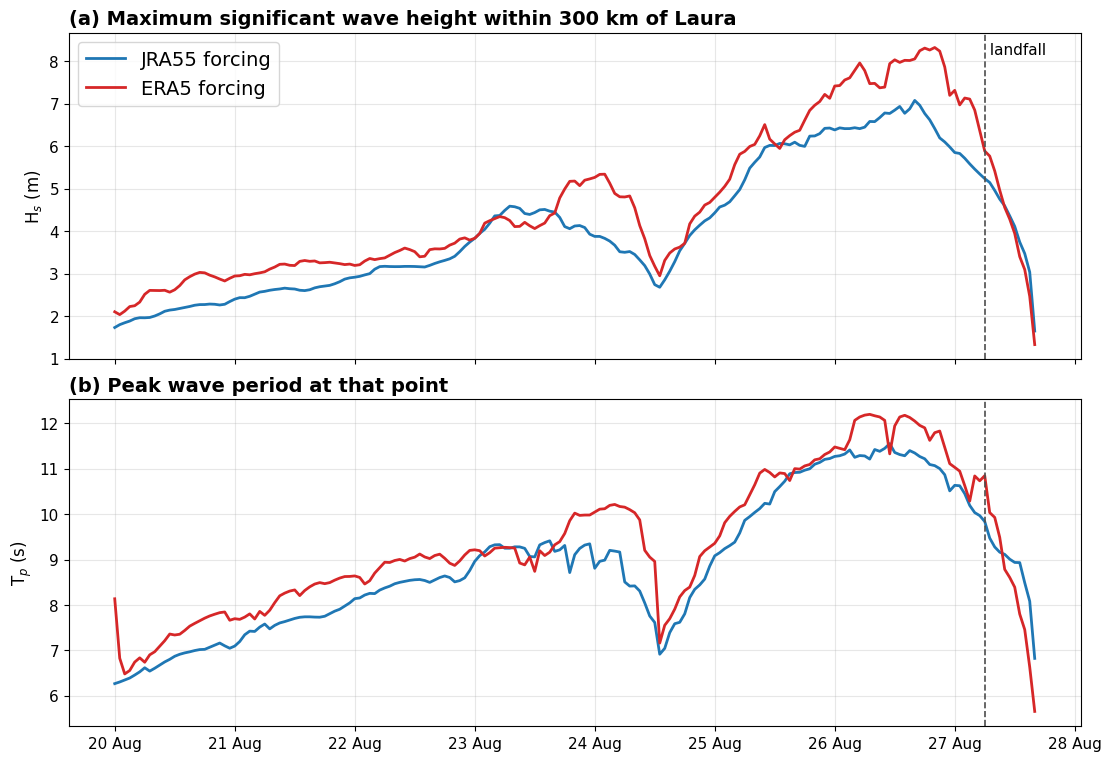

In [13]:
# Near-storm maximum significant wave height (a) and the peak wave period at that point (b)
colors = {"JRA55": "tab:blue", "ERA5": "tab:red"}
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, layout="constrained")
for name, df in storm_waves.items():
    ax1.plot(df.index, df["hs"], linewidth=2, color=colors[name], label=f"{name} forcing")
    ax2.plot(df.index, df["tp"], linewidth=2, color=colors[name], label=f"{name} forcing")
ax1.set_ylabel("H$_s$ (m)")
ax1.set_title(f"(a) Maximum significant wave height within {STORM_RADIUS_KM:.0f} km of Laura",
              loc="left", fontweight="bold")
ax1.legend(loc="upper left", fontsize=14)
ax2.set_ylabel("T$_p$ (s)")
ax2.set_title("(b) Peak wave period at that point", loc="left", fontweight="bold")
for ax in (ax1, ax2):
    ax.axvline(LANDFALL_TIME, color="0.3", linestyle="--", linewidth=1.2)
    ax.grid(alpha=0.3)
ax1.text(LANDFALL_TIME, 0.97, " landfall", transform=ax1.get_xaxis_transform(), va="top", fontsize=11)
ax2.xaxis.set_major_locator(mdates.DayLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.show()


## Model vs observations: SST, SSS and mixed-layer depth

The existing runs (`.001`) save daily-mean surface fields only; 3-D temperature and salinity are a single
mean over the run, too coarse for the storm. This section compares what the daily output allows:

- **SST**: model `tos` vs buoy water temperature (`WTMP`, ~1 m, daily mean) and the 0-5 m mean of each glider
  and Argo profile.
- **SSS**: model `sos` vs the 0-5 m mean salinity of glider and Argo profiles.
- **Mixed-layer depth**: model `mlotst` (depth where potential density exceeds the surface value by
  0.03 kg/m3) vs the same criterion applied to glider and Argo profiles (`MLD_DRHO`, density from UNESCO EOS-80).

Each observation is matched to the nearest wet model cell and the model day containing it. Glider and Argo
values are single profiles, the model values are daily means. Observations are those plotted in panel (c)
(within `TRACK_DISTANCE_DEG` of Laura). Profile comparisons on depth use the `.003` runs, which save 3-hourly
`thetao`, `so`, `uo`, `vo` on a fine z grid (`mom6.h.zfine`, 2 m spacing in the upper 50 m).

In [14]:
# Observed SST, SSS and MLD from buoys, gliders and Argo, with the daily model values at each observation
from scipy.spatial import cKDTree

MLD_DRHO = 0.03   # kg/m3 above the shallowest observation, as for MOM6 mlotst (HREF_FOR_MLD = 0)
MODEL_VAR = {"sst": "tos", "sss": "sos", "mld": "mlotst"}
VAR_LABEL = {"sst": "SST (\u00b0C)", "sss": "SSS (psu)", "mld": "Mixed-layer depth (m)"}


def open_sfc(case, variables=tuple(MODEL_VAR.values())):
    """Daily-mean surface fields of one case (time decoded as in open_sst)."""
    files = sorted(hist_dir(case).glob(f"{case}.mom6.h.sfc.*.nc"))
    ds = xr.open_mfdataset(files, combine="by_coords", decode_times=False)[list(variables)]
    time = decode_cf_datetime(ds["time"].values, ds["time"].attrs["units"], calendar="proleptic_gregorian")
    return ds.assign_coords(time=time).load()


sfc = {name: open_sfc(case) for name, case in EXPS.items()}
MODEL_DAYS = pd.DatetimeIndex(sfc["JRA55"]["time"].values).floor("D")

LON2D = ((static["geolon"].values + 180.0) % 360.0) - 180.0
LAT2D = static["geolat"].values
WET_J, WET_I = np.nonzero(WET.values)
_tree = cKDTree(np.column_stack([LON2D[WET_J, WET_I] * np.cos(np.deg2rad(LAT2D[WET_J, WET_I])),
                                 LAT2D[WET_J, WET_I]]))


def nearest_cell(lon, lat):
    """(j, i) of the nearest wet model cell to each point."""
    lon, lat = np.atleast_1d(np.asarray(lon, float)), np.atleast_1d(np.asarray(lat, float))
    _, k = _tree.query(np.column_stack([lon * np.cos(np.deg2rad(lat)), lat]))
    return WET_J[k], WET_I[k]


def model_at(lon, lat, time, var):
    """Daily-mean model var at the nearest wet cell and model day of each observation, per experiment."""
    j, i = nearest_cell(lon, lat)
    day = MODEL_DAYS.get_indexer(pd.DatetimeIndex(time).floor("D"))
    ok = day >= 0
    out = {}
    for name, ds in sfc.items():
        vals = np.full(len(j), np.nan)
        vals[ok] = ds[var].values[day[ok], j[ok], i[ok]]
        out[name] = vals
    return out


def sigma0(temp, salt):
    """Potential density anomaly (kg/m3), UNESCO EOS-80 at zero pressure."""
    t, s = np.asarray(temp, float), np.asarray(salt, float)
    rho_w = (999.842594 + 6.793952e-2 * t - 9.095290e-3 * t**2 + 1.001685e-4 * t**3
             - 1.120083e-6 * t**4 + 6.536332e-9 * t**5)
    return (rho_w + s * (0.824493 - 4.0899e-3 * t + 7.6438e-5 * t**2 - 8.2467e-7 * t**3 + 5.3875e-9 * t**4)
            + s**1.5 * (-5.72466e-3 + 1.0227e-4 * t - 1.6546e-6 * t**2) + 4.8314e-4 * s**2 - 1000.0)


def profile_summary(depth, temp, salt, zsurf=5.0, zref_max=10.0):
    """0-zsurf m mean temperature and salinity, and the depth where density first exceeds that at the
    shallowest level (which must be above zref_max) by MLD_DRHO."""
    d, t, s = (np.asarray(a, float) for a in (depth, temp, salt))
    good = np.isfinite(d) & np.isfinite(t) & np.isfinite(s)
    order = np.argsort(d[good])
    d, t, s = d[good][order], t[good][order], s[good][order]
    res = dict(sst=np.nan, sss=np.nan, mld=np.nan)
    if len(d) < 5 or d[0] > zref_max:
        return res
    top = d <= zsurf
    if top.any():
        res["sst"], res["sss"] = t[top].mean(), s[top].mean()
    rho = sigma0(t, s)
    deeper = np.nonzero(rho > rho[0] + MLD_DRHO)[0]
    if len(deeper):
        res["mld"] = d[deeper[0]]
    return res


def argo_profile(path):
    """Pressure, temperature and salinity of the first profile in an Argo file, adjusted values where
    available, keeping QC flags 1-2."""
    with xr.open_dataset(path, decode_times=False) as ds:
        out = {}
        for var in ("PRES", "TEMP", "PSAL"):
            adj = f"{var}_ADJUSTED"
            name = adj if adj in ds and np.isfinite(ds[adj].values[0]).any() else var
            vals = ds[name].values[0].astype(float)
            qc = ds[f"{name}_QC"].values[0].astype(str)
            vals[~np.isin(qc, ["1", "2"])] = np.nan
            out[var] = vals
    return out


rows = []
BUOY_HOURLY = {}
for station, info in BUOYS.iterrows():
    wtmp = read_ndbc(NDBC_DIR / "stdmet" / f"{station}h{YEAR}.txt.gz")["WTMP"].loc[T0:f"{T1} 23:59"].dropna()
    BUOY_HOURLY[station] = wtmp
    for day, v in wtmp.resample("D").mean().dropna().items():
        rows.append(dict(platform="Buoy", source=station, time=day + pd.Timedelta(hours=12),
                         lat=info["lat"], lon=info["lon"], sst=v, sss=np.nan, mld=np.nan))
for (src, pid), g in gliders.groupby(["source", "profile_id"]):
    rows.append(dict(platform="Glider", source=src, time=g["time"].median(), lat=g["lat"].mean(),
                     lon=g["lon"].mean(), **profile_summary(g["depth"], g["temp"], g["salt"])))
for _, a in ARGO.iterrows():
    p = argo_profile(ARGO_DIR / "profiles" / Path(a["file"]).name)
    rows.append(dict(platform="Argo", source=a["platform"], time=a["time"], lat=a["lat"], lon=a["lon"],
                     **profile_summary(p["PRES"], p["TEMP"], p["PSAL"])))
OBS = pd.DataFrame(rows)
for var, mvar in MODEL_VAR.items():
    for name, vals in model_at(OBS["lon"], OBS["lat"], OBS["time"], mvar).items():
        OBS[f"{var}_{name}"] = vals

stats = []
for var in MODEL_VAR:
    for platform, g in OBS.groupby("platform", sort=False):
        for name in EXPS:
            pair = g[[var, f"{var}_{name}"]].dropna()
            if len(pair) < 3:
                continue
            diff = pair[f"{var}_{name}"] - pair[var]
            stats.append(dict(Variable=VAR_LABEL[var], Platform=platform, N=len(pair), Forcing=name,
                              Bias=diff.mean(), RMSE=np.sqrt((diff**2).mean()),
                              r=np.corrcoef(pair[var], pair[f"{var}_{name}"])[0, 1]))
stats = pd.DataFrame(stats)
stats["Variable"] = pd.Categorical(stats["Variable"], [VAR_LABEL[v] for v in MODEL_VAR], ordered=True)
stats["Platform"] = pd.Categorical(stats["Platform"], ["Buoy", "Glider", "Argo"], ordered=True)
MODEL_OBS_STATS = (stats.pivot(index=["Variable", "Platform", "N"], columns="Forcing", values=["Bias", "RMSE", "r"])
                   .reorder_levels([1, 0], axis=1).reindex(columns=list(EXPS), level=0))
print(f"{len(OBS)} observations matched: " + ", ".join(f"{p} {n}" for p, n in OBS["platform"].value_counts().items()))
print("Model minus observation (Bias, RMSE) and correlation r:")
MODEL_OBS_STATS.round(2)

1279 observations matched: Glider 1167, Buoy 66, Argo 46
Model minus observation (Bias, RMSE) and correlation r:


Forcing                             JRA55               ERA5             
                                     Bias   RMSE     r  Bias   RMSE     r
Variable              Platform N                                         
SST (°C)              Buoy     66    0.07   0.20  0.94  0.07   0.22  0.93
                      Glider   810   0.03   0.27  0.87  0.01   0.21  0.91
                      Argo     41    0.21   0.33  0.96  0.13   0.29  0.96
SSS (psu)             Glider   810   0.14   0.77  0.46  0.16   0.73  0.50
                      Argo     41   -0.08   0.48  0.66 -0.06   0.47  0.65
Mixed-layer depth (m) Glider   1090  0.18   9.84  0.41 -0.55   9.98  0.38
                      Argo     44   -9.13  14.54  0.64 -8.66  14.51  0.60

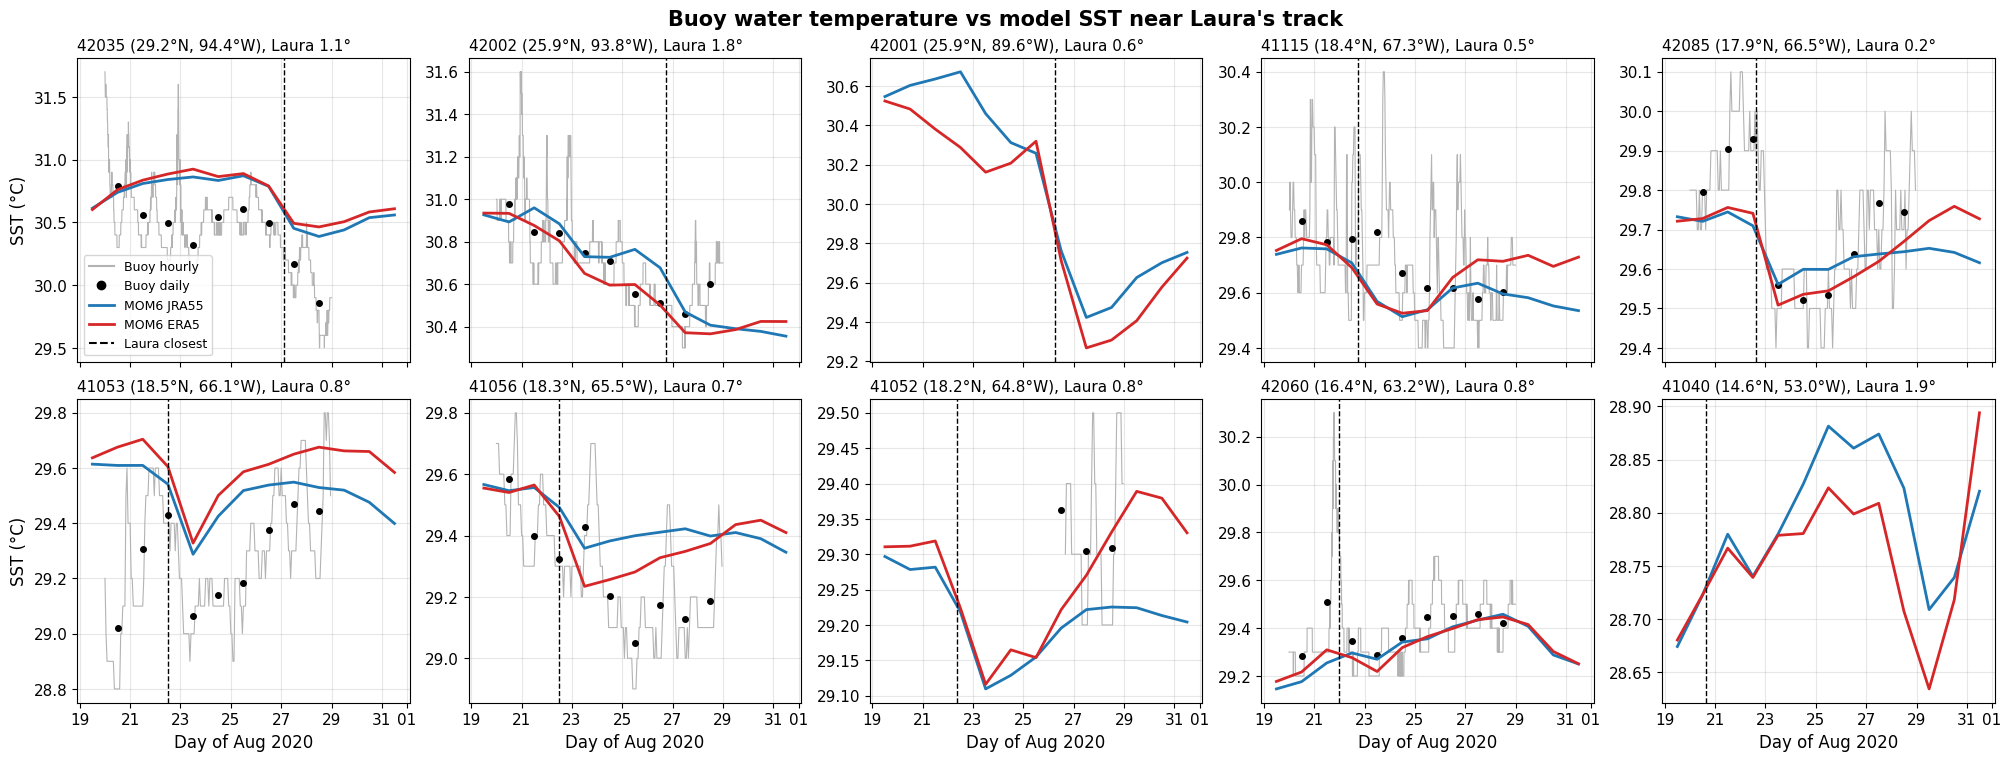

In [15]:
# SST at the buoys near Laura: hourly and daily observations vs daily model, with Laura's closest approach
def closest_approach(lon, lat):
    """Time and distance (deg) of Laura's nearest IBTrACS fix to a point."""
    d = np.hypot((TRACK["lon"] - lon) * np.cos(np.deg2rad(lat)), TRACK["lat"] - lat)
    return pd.Timestamp(TRACK["time"][np.argmin(d)]), d.min()


stations = BUOYS.sort_values("lon").index
ncol = 5
fig, axes = plt.subplots(int(np.ceil(len(stations) / ncol)), ncol, figsize=(20, 7.5), sharex=True,
                         layout="constrained", squeeze=False)
for ax, station in zip(axes.flat, stations):
    info = BUOYS.loc[station]
    j, i = nearest_cell(info["lon"], info["lat"])
    obs = BUOY_HOURLY[station]
    ax.plot(obs.index, obs.values, color="0.7", linewidth=0.8)
    daily = obs.resample("D").mean()
    ax.plot(daily.index + pd.Timedelta(hours=12), daily.values, "ko", markersize=4)
    for name, ds in sfc.items():
        ax.plot(ds["time"].values, ds["tos"].values[:, j[0], i[0]], color=SOURCE_STYLE[name][0], linewidth=2)
    t_ca, d_ca = closest_approach(info["lon"], info["lat"])
    ax.axvline(t_ca, color="k", linestyle="--", linewidth=1)
    ax.set_title(f"{station} ({info['lat']:.1f}\u00b0N, {-info['lon']:.1f}\u00b0W), Laura {d_ca:.1f}\u00b0",
                 fontsize=11, loc="left")
    ax.grid(alpha=0.3)
for ax in axes.flat[len(stations):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("SST (\u00b0C)")
for ax in axes[-1]:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d"))
    ax.set_xlabel("Day of Aug 2020")
axes.flat[0].legend(handles=[plt.Line2D([], [], color="0.7", label="Buoy hourly"),
                             plt.Line2D([], [], color="k", marker="o", linestyle="", label="Buoy daily"),
                             *[plt.Line2D([], [], color=SOURCE_STYLE[n][0], linewidth=2, label=f"MOM6 {n}")
                               for n in EXPS],
                             plt.Line2D([], [], color="k", linestyle="--", label="Laura closest")],
                    fontsize=9, loc="lower left")
fig.suptitle("Buoy water temperature vs model SST near Laura's track", fontsize=15, fontweight="bold")
plt.show()

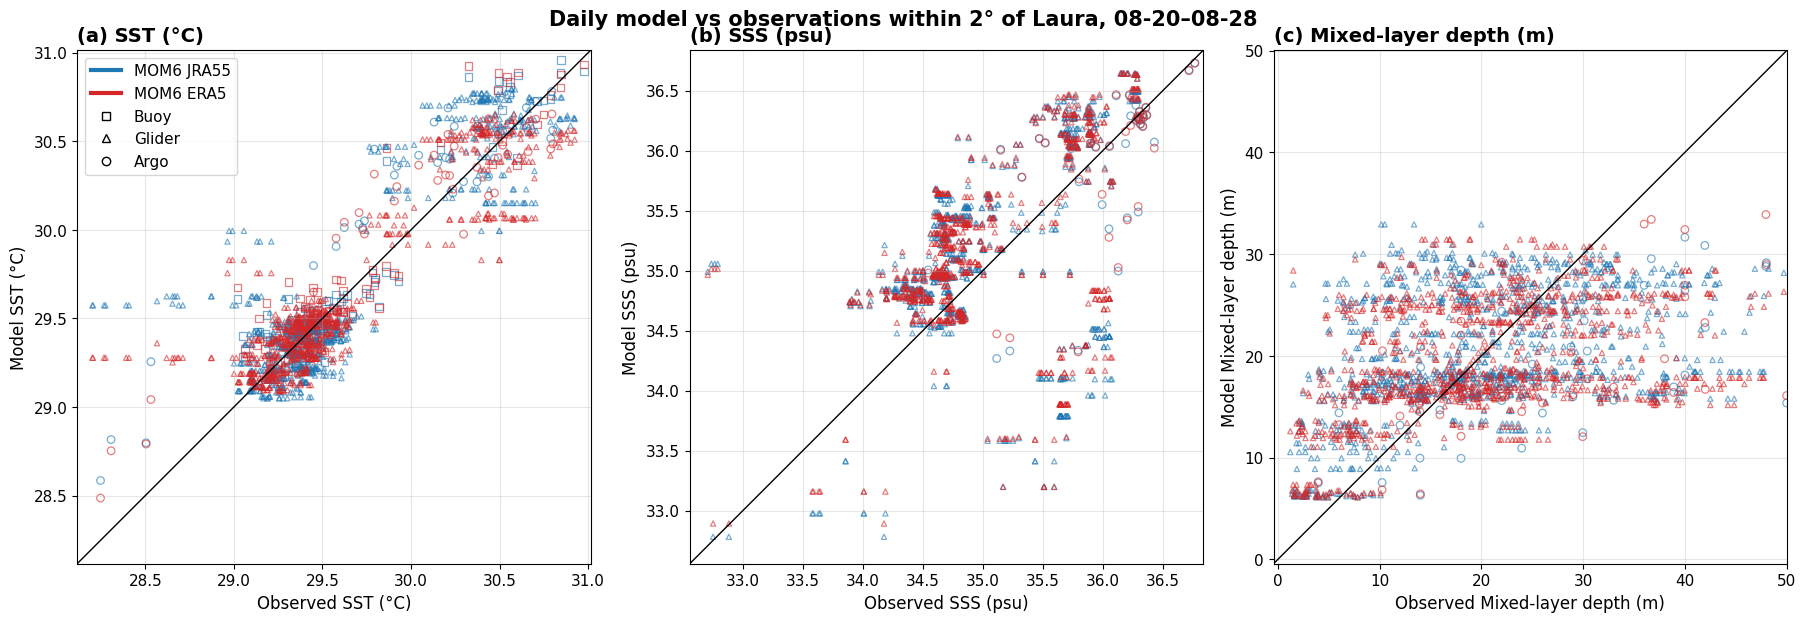

In [16]:
# Model vs observed SST, SSS and mixed-layer depth for all matched observations
PLATFORM_MARKER = {"Buoy": "s", "Glider": "^", "Argo": "o"}
fig, axes = plt.subplots(1, 3, figsize=(18, 6), layout="constrained")
for ax, var in zip(axes, MODEL_VAR):
    vals = []
    for platform, g in OBS.groupby("platform", sort=False):
        for name in EXPS:
            pair = g[[var, f"{var}_{name}"]].dropna()
            if pair.empty:
                continue
            ax.scatter(pair[var], pair[f"{var}_{name}"], s=14 if platform == "Glider" else 30,
                       marker=PLATFORM_MARKER[platform], facecolors="none",
                       edgecolors=SOURCE_STYLE[name][0], linewidths=0.9, alpha=0.6)
            vals += [pair[var].values, pair[f"{var}_{name}"].values]
    lo, hi = np.nanpercentile(np.concatenate(vals), [0.5, 99.5])
    pad = 0.05 * (hi - lo)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], "k-", linewidth=1)
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_aspect("equal")
    ax.set_xlabel(f"Observed {VAR_LABEL[var]}")
    ax.set_ylabel(f"Model {VAR_LABEL[var]}")
    ax.grid(alpha=0.3)
axes[0].legend(handles=[*[plt.Line2D([], [], color=SOURCE_STYLE[n][0], linewidth=3, label=f"MOM6 {n}") for n in EXPS],
                        *[plt.Line2D([], [], marker=m, linestyle="", markerfacecolor="none", markeredgecolor="k",
                                     label=p) for p, m in PLATFORM_MARKER.items()]],
               fontsize=11, loc="upper left")
for ax, label in zip(axes, "abc"):
    ax.set_title(f"({label}) {VAR_LABEL[list(MODEL_VAR)[ord(label) - 97]]}", loc="left", fontweight="bold")
fig.suptitle(f"Daily model vs observations within {TRACK_DISTANCE_DEG:.0f}\u00b0 of Laura, {T0[5:]}\u2013{T1[5:]}",
             fontsize=15, fontweight="bold")
plt.show()

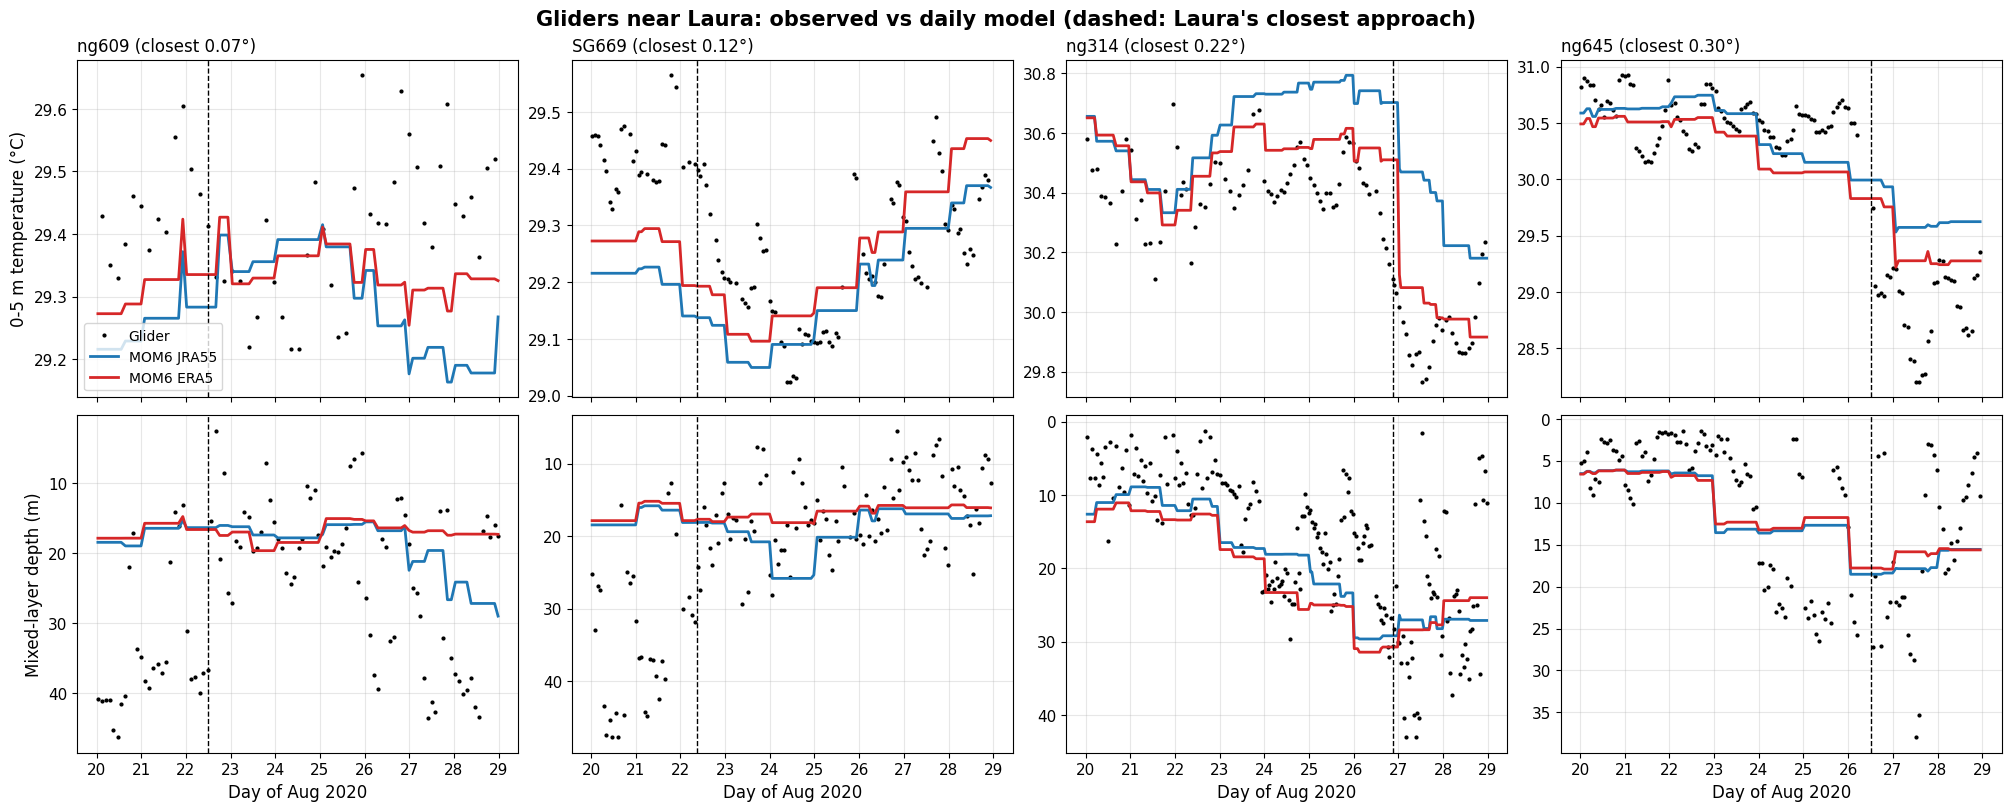

In [17]:
# Near-surface temperature and mixed-layer depth along the four gliders closest to Laura's track
NEAR_GLIDERS = sorted(GLIDER_TRACKS, key=closest.get)[:4]
fig, axes = plt.subplots(2, len(NEAR_GLIDERS), figsize=(20, 8), sharex=True, layout="constrained", squeeze=False)
for col, dsid in enumerate(NEAR_GLIDERS):
    g = OBS[(OBS["platform"] == "Glider") & (OBS["source"] == dsid)].sort_values("time")
    track = GLIDER_TRACKS[dsid]
    k = np.argmin(distance_to_track_deg(track["lon"], track["lat"]))
    t_ca, d_ca = closest_approach(track["lon"].iloc[k], track["lat"].iloc[k])
    for row, var in enumerate(("sst", "mld")):
        ax = axes[row, col]
        ax.plot(g["time"], g[var], "k.", markersize=4, label="Glider")
        for name in EXPS:
            ax.plot(g["time"], g[f"{var}_{name}"], color=SOURCE_STYLE[name][0], linewidth=2, label=f"MOM6 {name}")
        ax.axvline(t_ca, color="k", linestyle="--", linewidth=1)
        ax.grid(alpha=0.3)
        if col == 0:
            ax.set_ylabel(VAR_LABEL[var].replace("SST", "0-5 m temperature"))
    axes[0, col].set_title(f"{dsid.split('-')[0]} (closest {closest[dsid]:.2f}\u00b0)", loc="left", fontsize=12)
    axes[1, col].invert_yaxis()
    axes[1, col].xaxis.set_major_formatter(mdates.DateFormatter("%d"))
    axes[1, col].set_xlabel("Day of Aug 2020")
axes[0, 0].legend(fontsize=10, loc="lower left")
fig.suptitle("Gliders near Laura: observed vs daily model (dashed: Laura's closest approach)",
             fontsize=15, fontweight="bold")
plt.show()

## Representative points: forcing and ocean response, JRA55 vs ERA5 vs observations

Three NDBC buoys sampling different parts of Laura's path: 42001 (deep Gulf, near the track), 42035 (shelf,
left of the track near landfall) and 42039 (shelf, far field to the right). At each: 10 m wind speed from the
DATM forcing, significant wave height from WW3 (`.002` runs, hourly) and daily SST from MOM6 (`.001` runs);
the table adds minimum sea-level pressure. Buoy winds are measured at ~4 m and adjusted to 10 m with a neutral
log profile (roughness length 0.1 mm, factor ~1.08); buoy water temperature is measured at ~1 m.


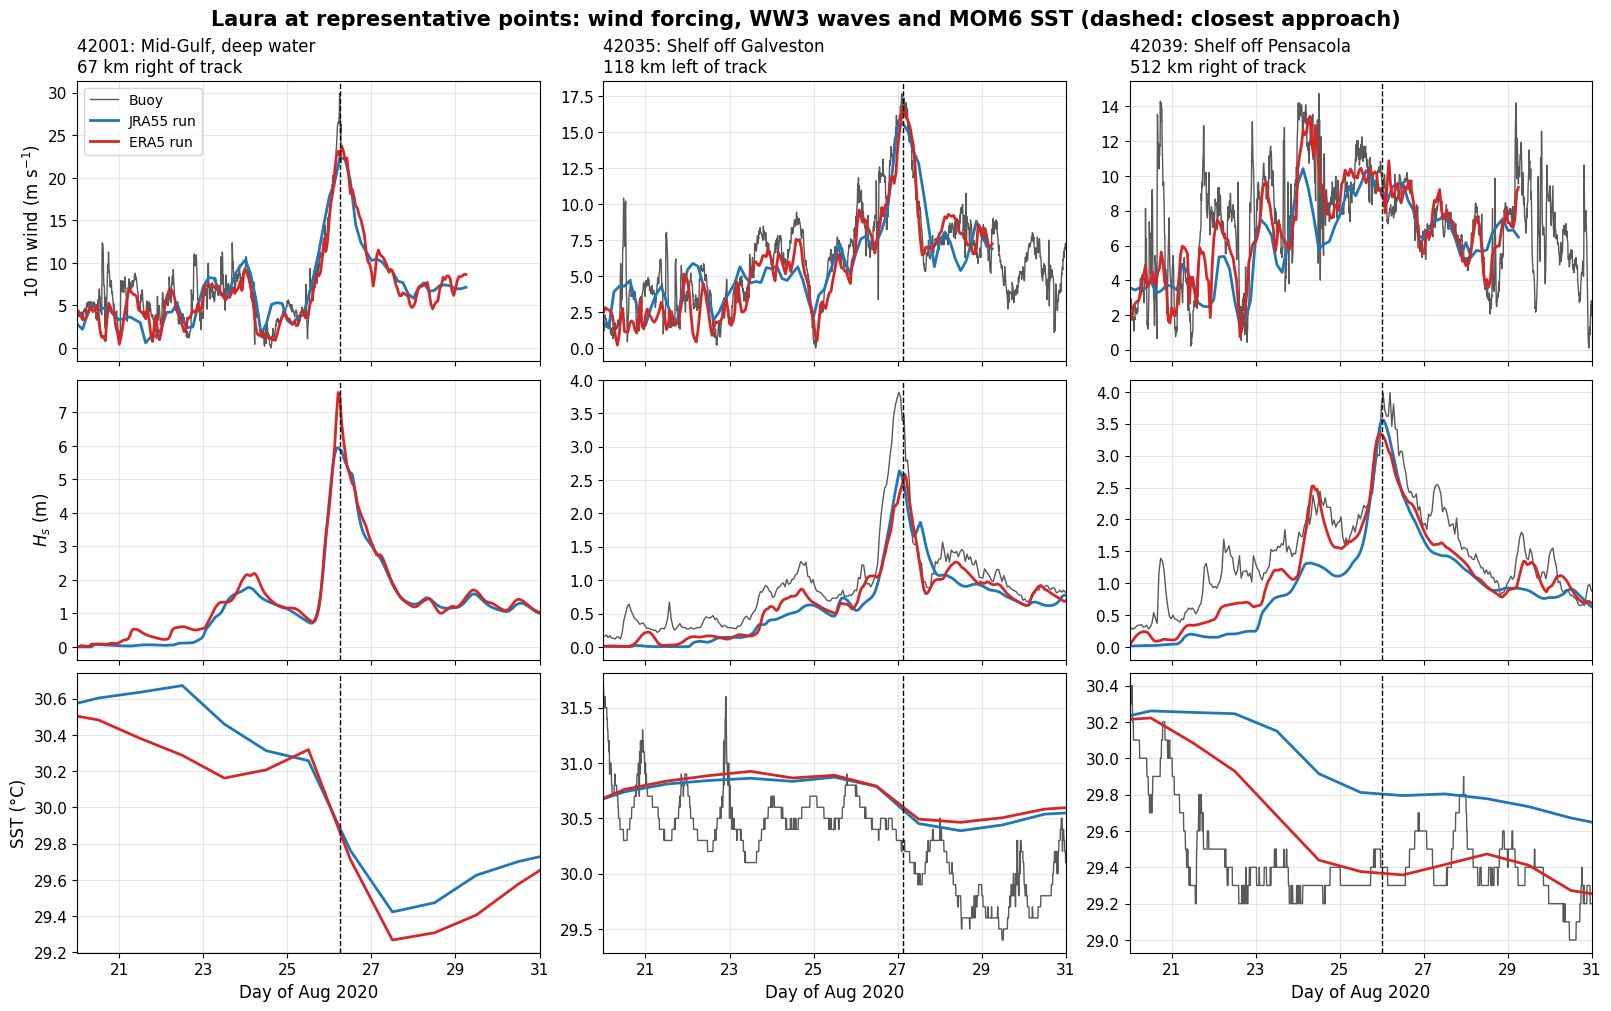

Max wind (m/s)  Min SLP (hPa)  Max Hs (m)  \
Point                Source                                              
42001 (67 km right)  Buoy             29.92         990.50         NaN   
                     JRA55            22.40        1001.54        5.94   
                     ERA5             23.72         996.16        7.59   
42035 (118 km left)  Buoy             17.67         997.90        3.81   
                     JRA55            15.57        1000.84        2.64   
                     ERA5             16.77         998.79        2.59   
42039 (512 km right) Buoy             14.74        1010.10        3.99   
                     JRA55            10.42        1012.41        3.56   
                     ERA5             13.43        1011.22        3.34   

                             ΔSST (°C)  
Point                Source             
42001 (67 km right)  Buoy          NaN  
                     JRA55       -0.78  
                     ERA5        -0.94  
42035 (118 km left)  Buoy        -0.72  
                     JRA55       -0.37  
                     ERA5        -0.32  
42039 (512 km right) Buoy         0.12  
                     JRA55       -0.07  
                     ERA5         0.01

In [18]:
# Forcing, waves and SST at representative points: JRA55 and ERA5 runs vs NDBC buoys
POINT_STATIONS = {
    "42001": "Mid-Gulf, deep water",
    "42035": "Shelf off Galveston",
    "42039": "Shelf off Pensacola",
}
ANEMOMETER_HEIGHT, Z0 = 4.1, 1e-4    # m
U10_FACTOR = np.log(10.0 / Z0) / np.log(ANEMOMETER_HEIGHT / Z0)
OBS_END = "2020-08-31 23:59"

station_table = ndbc_station_table()
POINTS = {}
for st, desc in POINT_STATIONS.items():
    if st == STONE_MOORING["station"]:
        lat, lon = STONE_MOORING["lat"], STONE_MOORING["lon"]
    else:
        lat, lon = station_table.loc[st, ["lat", "lon"]]
    POINTS[st] = dict(desc=desc, lat=float(lat), lon=float(lon))


def track_offset(lon, lat):
    """Closest-approach time, distance (km) and side of Laura's track ('right'/'left' of its motion)."""
    tlon, tlat = np.asarray(TRACK["lon"], float), np.asarray(TRACK["lat"], float)
    c = np.cos(np.deg2rad(lat))
    d = np.hypot((tlon - lon) * c, tlat - lat)
    k = int(np.argmin(d))
    k0, k1 = max(k - 1, 0), min(k + 1, len(tlon) - 1)
    mx, my = (tlon[k1] - tlon[k0]) * c, tlat[k1] - tlat[k0]
    px, py = (lon - tlon[k]) * c, lat - tlat[k]
    side = "right" if mx * py - my * px < 0 else "left"
    return pd.Timestamp(TRACK["time"][k]), d[k] * 111.0, side


def point_series(p):
    """Observed and modelled series at one point: dict of variable -> {source: pd.Series}."""
    j, i = nearest_cell(p["lon"], p["lat"])
    out = {v: {} for v in ("wspd", "slp", "hs", "sst")}
    for name in EXPS:
        slp, wspd = forcing[name]
        pt = dict(lon=p["lon"] % 360.0, lat=p["lat"], method="nearest")
        out["slp"][name] = slp.sel(**pt).to_series()
        out["wspd"][name] = wspd.sel(**pt).to_series()
        out["hs"][name] = pd.Series(waves[name]["HS"].values[:, j[0], i[0]], index=pd.DatetimeIndex(WAVE_TIMES))
        out["sst"][name] = pd.Series(sfc[name]["tos"].values[:, j[0], i[0]], index=pd.DatetimeIndex(sfc[name]["time"].values))
    path = NDBC_DIR / "stdmet" / f"{p['station']}h{YEAR}.txt.gz" if "station" in p else None
    if path is not None and path.exists():
        buoy = read_ndbc(path).loc[T0:OBS_END]
        for var, col, scale in (("wspd", "WSPD", U10_FACTOR), ("slp", "PRES", 1.0), ("hs", "WVHT", 1.0),
                                ("sst", "WTMP", 1.0)):
            s = buoy[col].dropna() * scale
            if not s.empty:
                out[var]["Buoy"] = s
    return out


for st, p in POINTS.items():
    p["station"] = st
    p["t_ca"], p["dist_km"], p["side"] = track_offset(p["lon"], p["lat"])
    p["series"] = point_series(p)

# Time series
ROWS = {"wspd": "10 m wind (m s$^{-1}$)", "hs": "$H_s$ (m)", "sst": "SST (\u00b0C)"}
STYLE = {"Buoy": dict(color="0.35", linewidth=1.0), **{n: dict(color=SOURCE_STYLE[n][0], linewidth=2.0) for n in EXPS}}
fig, axes = plt.subplots(len(ROWS), len(POINTS), figsize=(16, 10), sharex=True, layout="constrained")
for col, (st, p) in enumerate(POINTS.items()):
    for row, var in enumerate(ROWS):
        ax = axes[row, col]
        for src in ("Buoy", *EXPS):
            s = p["series"][var].get(src)
            if s is not None:
                ax.plot(s.index, s.values, label=src if src == "Buoy" else f"{src} run", **STYLE[src])
        ax.axvline(p["t_ca"], color="k", linestyle="--", linewidth=1)
        ax.set_xlim(pd.Timestamp(T0), pd.Timestamp("2020-08-31"))
        ax.grid(alpha=0.3)
        if col == 0:
            ax.set_ylabel(ROWS[var])
    axes[0, col].set_title(f"{st}: {p['desc']}\n{p['dist_km']:.0f} km {p['side']} of track", loc="left", fontsize=12)
    axes[-1, col].xaxis.set_major_formatter(mdates.DateFormatter("%d"))
    axes[-1, col].set_xlabel("Day of Aug 2020")
axes[0, 0].legend(fontsize=10, loc="upper left")
fig.suptitle("Laura at representative points: wind forcing, WW3 waves and MOM6 SST (dashed: closest approach)",
             fontsize=15, fontweight="bold")
plt.show()

# Summary: peak wind, minimum SLP, peak Hs, and SST change (2 days after minus 2 days before closest approach)
rows = []
for st, p in POINTS.items():
    t0, t1 = p["t_ca"] - pd.Timedelta(days=2), p["t_ca"] + pd.Timedelta(days=2)
    for src in ("Buoy", *EXPS):
        r = {"Point": f"{st} ({p['dist_km']:.0f} km {p['side']})", "Source": src}
        for var, label, how in (("wspd", "Max wind (m/s)", "max"), ("slp", "Min SLP (hPa)", "min"),
                                ("hs", "Max Hs (m)", "max")):
            s = p["series"][var].get(src)
            r[label] = getattr(s.loc[t0:t1], how)() if s is not None else np.nan
        s = p["series"]["sst"].get(src)
        if s is not None:
            daily = s.resample("D").mean()
            pre = daily.loc[t0.floor("D"):p["t_ca"].floor("D") - pd.Timedelta(days=1)].mean()
            post = daily.loc[p["t_ca"].ceil("D"):t1.ceil("D")].mean()
            r["\u0394SST (\u00b0C)"] = post - pre
        rows.append(r)
POINT_SUMMARY = pd.DataFrame(rows).set_index(["Point", "Source"])
POINT_SUMMARY.round(2)